# Mono-$Z$ karanlık madde araması: veri, kurulum, BDT/DNN/NSF karşılaştırması

**TÜBİTAK 2209-A ara rapor defteri.** CMS Open Data (`RunIIFall15MiniAODv2`,
$\sqrt{s}=13$ TeV, $\mathcal{L}=2.32$ fb$^{-1}$) üzerinde
$pp\to Z\chi\bar\chi$, $Z\to\ell^+\ell^-$ kanalı.

Üç sınıflandırıcı **aynı olayları, aynı öznitelikleri, aynı bölünmeleri ve aynı
tohumları** kullanır; tek fark olabilirlik oranının nasıl kestirildiğidir:

| Yöntem | Kestirilen nicelik | Tür |
| --- | --- | --- |
| BDT | $p(S\mid x)$ | ayırt edici (discriminative) |
| DNN | $p(S\mid x)$ | ayırt edici |
| NSF | $p(x\mid S)$ ve $p(x\mid B)$ ayrı ayrı | üretici (yoğunluk kestirimi) |

Neyman–Pearson lemması en güçlü testin olabilirlik oranı
$\Lambda(x)=p(x\mid S)/p(x\mid B)$ ile verildiğini söyler. Ayırt edici modellerde bu
oran sınıf sonsalından, sabit öncellerle, tersine çevrilerek elde edilir:

$$\Lambda(x)=\frac{p(S\mid x)}{1-p(S\mid x)}\cdot\frac{1-\pi}{\pi},
\qquad
s_{\rm NSF}(x)=\log p(x\mid S)-\log p(x\mid B)=\log\Lambda(x)$$

*Kaynak:* J. Neyman, E. S. Pearson, Phil. Trans. R. Soc. A **231** (1933) 289;
K. Cranmer, J. Pavez, G. Louppe, arXiv:1506.02169.

## 0. Veri kaynağı

Girdilerin tamamı CERN Open Data Portal'dan alınan `RunIIFall15MiniAODv2` campaign'i
`MINIAODSIM` örnekleridir (2015, $\sqrt{s}=13$ TeV $pp$; koşul etiketi
`PU25nsData2015v1_76X_mcRun2_asymptotic_v12`; `CMSSW_7_6_7`). Gerçek çarpışma verisi
kullanılmamıştır.

| Rol | Veri kümesi | Kayıt | Dosya | $\sigma$ [pb] |
| --- | --- | --- | ---: | ---: |
| arka plan | `DYJetsToLL_M-50` (aMC@NLO) | [16458](https://opendata.cern.ch/record/16458) | † | 5932 |
| arka plan | `ZZTo2L2Nu` (POWHEG) | [21593](https://opendata.cern.ch/record/21593) | 2 | 0.5644 |
| arka plan | `WZTo3LNu` (POWHEG) | [20687](https://opendata.cern.ch/record/20687) | 3 | 4.102 |
| arka plan | `TTTo2L2Nu` (POWHEG) | [19958](https://opendata.cern.ch/record/19958) | 2 | 76.69 |
| arka plan | `ST_tW_top_5f` (POWHEG) | [19419](https://opendata.cern.ch/record/19419) | 3 | 38.09 |
| arka plan | `ST_tW_antitop_5f` (POWHEG) | [19412](https://opendata.cern.ch/record/19412) | 3 | 38.06 |
| sinyal | `MonoZToLL_A_Mx-10_Mv-20` | [16575](https://opendata.cern.ch/record/16575) | 1 | 1.856 |
| sinyal | `MonoZToLL_A_Mx-50_Mv-200` | [16597](https://opendata.cern.ch/record/16597) | 3 | 0.158 |
| sinyal | `MonoZToLL_V_Mx-1_Mv-500` | [16630](https://opendata.cern.ch/record/16630) | 1 | 0.0273 |
| sinyal | `MonoZToLL_EWK_Scalar_Mx-100_Lambda-3000` | [16601](https://opendata.cern.ch/record/16601) | 1 | $9.9\times10^{-8}$ |

Sinyal DOI'leri: `10.7483/OPENDATA.CMS.{YB3Q.XTXY, 34IE.KN6I, YTLH.E0N7, NW7F.NFGG}`.

**Kaynak seçimi.** `DarkMatter_MonoZToLL` örnekleri yalnızca `RunIIFall15` campaign'inde
yayımlanmıştır; Run-2 Ultra-Legacy'de arka planların karşılığı bulunsa da bu sinyal ailesi
yoktur (UL16'daki karanlık madde örnekleri `DM_MonoZPrime`, farklı bir modeldir). Sinyal ve
arka planın aynı campaign'den seçilmesi, pile-up profili ve rekonstrüksiyon sürümünün ortak
olmasını sağlar. MINIAOD formatı gerekli PAT nesnelerini içerir; bu campaign'in NanoAOD'u
yayımlanmamıştır. Dört sinyal noktası referans analizle (Rasineni & Chebrolu, Tablo 5)
örtüşmektedir. Dosya bütünlüğü `adler32` ile doğrulanır (`_indir.py`); kullanılan dosyaların
listesi `_dosyalar.json` içindedir.

† DY'nin dosya sayısı sabit değildir: kayıtta ~2890 dosya vardır ve istatistik artırmak için
zamanla daha fazlası indirildi (ilk sürümde 10 dosya, $N_{\rm gen}=497\,974$; şimdi
$N_{\rm gen}$ §1a tablosunda). Bu yüzden sayı tabloya elle yazılmaz; güncel dosya sayıları
aşağıdaki hücrede `_dosyalar.json`'dan sayılır.

**Üretici farkı tutarsızlık değildir.** DY `amcatnloFXFX`, diğer beş arka plan
`powheg` ile üretilmiştir; bu CMS'in sürece özgü standart seçimidir --
Drell--Yan çok-jet birleştirme (FxFx) gerektirir, diboson/$t\bar t$/$tW$
gerektirmez. Tam veri kümesi adları doğrulandı: hepsi aynı `pythia8` parton
gölgelemesini ve aynı `RunIIFall15MiniAODv2-PU25nsData2015v1_76X_mcRun2_asymptotic_v12`
campaign etiketini taşıyor (DY'de `_ext4` soneki yalnızca ek istatistik üretimi
anlamına gelir, koşulları değiştirmez).

**Süreç kapsamı.** Mono-$Z$ imzası iki ters yüklü aynı tatta lepton ve $E_T^{\rm miss}$'tir.
$ZZ\to2\ell2\nu$ indirgenemezdir. $WZ\to3\ell\nu$, bir lepton kaybedildiğinde indirgenemez
hâle gelir. Drell–Yan'da gerçek $E_T^{\rm miss}$ bulunmaz; ancak tesir kesiti $10^3$–$10^4$
kat büyük olduğundan çözünürlükten doğan sahte $E_T^{\rm miss}$ kuyruğu baskın arka planı
oluşturur. $t\bar t$, $tW$ ve $\bar tW$ iki gerçek $W\to\ell\nu$ içerir ve $Z$ kütle
penceresiyle kısmen bastırılır. Tek lepton sahteleri ($W$+jet, QCD) izolasyon ve kütle
penceresi sonrası ihmal edilebilir düzeydedir.

In [1]:
# §0 tablosundaki dosya sayilari _dosyalar.json'dan sayilir; yeni dosya
# indirildikce kendiliginden guncellenir.
import json
from pathlib import Path


def _root_say(o):
    """JSON icindeki .root dosya adlarini sayar (yapidan bagimsiz)."""
    if isinstance(o, dict):
        return sum(_root_say(v) for v in o.values())
    if isinstance(o, list):
        return sum(_root_say(v) for v in o)
    return int(isinstance(o, str) and o.endswith('.root'))


_yol = Path('/work/_dosyalar.json')
if _yol.exists():
    _liste = json.load(open(_yol))
    if isinstance(_liste, dict):
        for _k, _v in _liste.items():
            print(f'{_k:50s} {_root_say(_v):5d} dosya')
    print(f'toplam {_root_say(_liste)} .root dosyasi')
else:
    print(f'{_yol} bulunamadi')

DY                                                    27 dosya
A(50,200)                                              3 dosya
toplam 30 .root dosyasi


## 1a. Olay ağırlığı ve tesir kesiti normalizasyonu

$$w \;=\; w_{\rm gen}\cdot
\frac{\sigma_{\rm pb}\,\mathcal{L}_{\rm fb^{-1}}\times 1000}{\sum w_{\rm gen}}
\cdot w_{\rm PU}\cdot SF_{\mu_1}\cdot SF_{\mu_2},
\qquad w_{\rm data}=1$$

$\sigma\mathcal{L}\times1000$ çarpımı beklenen olay sayısını verir; $1000$ katsayısı
$\mathcal{L}$'yi fb$^{-1}$'den pb$^{-1}$'ye çevirerek çarpımı boyutsuz kılar. Payda
$\sum w_{\rm gen}$ kesim öncesi tüm olaylar üzerinden alınır. $w_{\rm gen}/\sum w_{\rm gen}$
oranı olayın örnek içindeki payıdır; beklenen olay sayısı bu payla ölçeklendiğinde tek bir MC
olayının temsil ettiği gerçek olay sayısı elde edilir.

$\mathcal{L}=2.32$ fb$^{-1}$ için $\sigma$, $\sum w_{\rm gen}$, $N_{\rm gen}$,
$\sigma\mathcal{L}$ ve olay başına ağırlık kurulum hücresinden hemen sonra **veriden
hesaplanır** (`agirlik_tablosu.csv`); indirilen dosya sayısı değişince tablo kendiliğinden
güncellenir.

DY'nin olay başına ağırlığı $ZZ$'ninkinden yüzlerce kat büyüktür (oran tablonun altında
yazdırılır). Bu fark üç sonuç doğurur: (i) DY histogramlarda kesikli görünür, her DY olayı
büyük bir katkı yapar; (ii) etkin örneklem büyüklüğü $N_{\rm eff}$ düşer ve anlamlılık
taraması ham olay sayısı yerine $N_{\rm eff}$ ile korunmalıdır (§2); (iii) DY'nin MC
istatistik belirsizliği baskın olur.

**Üretici ağırlıkları.** DY tek `amcatnloFXFX` örneğidir ve olaylarının bir kısmı negatif
ağırlıklıdır (payı tabloda, ön seçilmiş olaylar üzerinden); $\lvert w_{\rm gen}\rvert$
bütün DY olaylarında tek bir değer alır (23 443.4). Negatif ağırlıklar NLO eşleştirmede çift
sayımı önler. $\sum w_{\rm gen}/N_{\rm gen}$ oranı işaret dengesinden gelir ve negatif pay
$f$ ise yaklaşık $1-2f$'ye eşit olmalıdır; iki sayı tablonun altında karşılaştırılır.
Diğer beş arka plan (POWHEG) ve dört sinyal (MADGRAPH) örneğinde $w_{\rm gen}\equiv1$'dir.

**Ölçek çarpanları.** $w_{\rm PU}$ ve $SF_\mu$ bu çalışmada $1$ alınmıştır. Her iki çarpanın
işlevi simülasyonu veriye uyarlamaktır; gerçek veri kullanılmadığından referans yoktur.
Ayrıca sinyal ve arka plana aynı yönde uygulandıkları için $S/B$ oranında ve dolayısıyla
$Z_A$'da büyük ölçüde sadeleşirler. Veri/MC karşılaştırması veya veri üzerinden mutlak limit
çıkarımı yapılması hâlinde gerekli olurlar.

*Kaynak:* N. Bostan, *Event Weight Summary* (grup sunumu). Uygulama: `_extract.py`
(`generator_weights`, `load`); ölçüm: `_dy_tani2.py`.

In [2]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import uproot
import awkward as ak
import zuko
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import log_loss, roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

LUMI = 2320.0          # pb^-1, CMS Run 2015D
MZ = 91.1876           # GeV
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
OUT = '/work/results/'
exec(open('/work/_extract.py').read())   # load, BKG, SIG, KUNYE, cell_resample, neff_bins

plt.rcParams.update({
    'xtick.direction': 'in', 'ytick.direction': 'in',   # centikler ice donuk
    'xtick.top': True, 'ytick.right': True,             # dort kenarda centik
    'xtick.minor.visible': True, 'ytick.minor.visible': True,
    'axes.linewidth': 1.5,                              # kalin cerceve
    'font.family': 'serif', 'font.size': 12,
    'axes.grid': False,
})

print('arka planlar :', list(BKG.keys()))
print('sinyaller    :', list(SIG.keys()))

arka planlar : ['DY', 'ZZ', 'WZ', 'ttbar', 'tW_top', 'tW_antitop']
sinyaller    : ['axial (10, 20)', 'axial (50, 200)', 'vector (1, 500)', 'scalar (100, 3000)']


In [3]:
# 1a tablosu: N_gen ve sum_w load'un ozet satirindan okunur, sigma ise
# w = w_gen * sigma / sum_w bagintisindan geri cozulur (w_PU = SF = 1).
import io, re, contextlib


def kunye(ad, kaynak):
    tampon = io.StringIO()
    with contextlib.redirect_stdout(tampon):
        d = load({ad: kaynak})
    satir = tampon.getvalue()
    oku = lambda k: float(re.search(k + r'=\s*([-\d.eE+]+)', satir).group(1))
    n_gen, sum_w = oku('N_gen'), oku('sum_w')
    sigma = (d.weight / d.w_gen).iloc[0] * sum_w
    return {'ornek': ad, 'sigma [pb]': sigma, 'sum w_gen': sum_w,
            'N_gen': int(n_gen), 'sigma*L': sigma * LUMI,
            'olay basina': d.weight.abs().median() * LUMI,
            'negatif %': 100 * (d.w_gen < 0).mean()}


agirlik = pd.DataFrame([kunye(k, v) for k, v in {**BKG, **SIG}.items()])
agirlik = agirlik.set_index('ornek')
agirlik.to_csv(OUT + 'agirlik_tablosu.csv')
print(agirlik.to_string(float_format=lambda x: f'{x:.4g}'))
_dy, _zz = agirlik.loc['DY'], agirlik.loc['ZZ']
print(f"\nDY / ZZ olay basina agirlik orani: "
      f"{_dy['olay basina'] / _zz['olay basina']:.0f}")
print(f"DY sum_w / N_gen = {_dy['sum w_gen'] / _dy['N_gen']:.3f};  "
      f"1 - 2 x negatif pay = {1 - 2 * _dy['negatif %'] / 100:.3f}")

                    sigma [pb]  sum w_gen    N_gen   sigma*L  olay basina  negatif %
ornek                                                                               
DY                        5932  2.067e+10  1315027 1.376e+07        15.61      15.79
ZZ                      0.5644  6.302e+04    63025      1309      0.02078          0
WZ                       4.102  9.516e+04    95164      9516      0.09999          0
ttbar                    76.69  5.623e+04    56227 1.779e+05        3.164          0
tW_top                   38.09  1.056e+05   105600 8.837e+04       0.8368          0
tW_antitop               38.06    1.1e+05   110000  8.83e+04       0.8027          0
axial (10, 20)           1.856      5e+04    50000      4306      0.08612          0
axial (50, 200)          0.158      5e+04    50000     366.6     0.007331          0
vector (1, 500)        0.02735      5e+04    50000     63.44     0.001269          0
scalar (100, 3000)   9.919e-08      5e+04    50000 0.0002301    4

## 1b. $ZZ$ üzerinden bir bakış (SR kesimi öncesi)

In [4]:
zz = load({'ZZ': BKG['ZZ']})

print('boyut (olay, sutun):', zz.shape)
print()
for i, c in enumerate(zz.columns, start=1):
    print(f'{i:2d}. {c}')
print()
print(zz[['met', 'Z_pt', 'm_ll', 'dphi_Z_met', 'n_jets', 'weight']].head())
print()
print(zz[['met', 'm_ll', 'dphi_Z_met', 'n_jets']].describe().round(2))

ZZ                 N_gen=  63025  sum_w=  63025.0  selected= 17856  sigma=   0.5644 pb  yield=    371.0  [onbellek]
boyut (olay, sutun): (17856, 40)

 1. met
 2. met_phi
 3. min_dphi_met_jets
 4. dphi_met_jet1
 5. dphi_met_jet2
 6. met_over_sqrtHT
 7. hadronic_recoil_pt
 8. m_ll
 9. Z_pt
10. Z_eta
11. Z_phi
12. dphi_Z_met
13. met_over_ptZ
14. abs_met_minus_ptZ
15. abs_mll_minus_mZ
16. u_parallel
17. u_perp
18. u_parallel_over_ptZ
19. u_perp_over_ptZ
20. lep1_pt
21. lep1_eta
22. lep2_pt
23. lep2_eta
24. dR_ll
25. dphi_ll
26. lep1_reliso
27. lep2_reliso
28. cos_theta_star
29. dphi_met_lep1
30. jet1_pt
31. jet1_eta
32. jet2_pt
33. jet2_eta
34. has_jet1
35. has_jet2
36. n_jets
37. mT
38. w_gen
39. weight
40. process

          met        Z_pt       m_ll  dphi_Z_met  n_jets    weight
0   70.712807   87.587038  90.967536    2.899987       0  0.000009
1   54.893635   51.504695  91.447124    2.955057       0  0.000009
2  102.147560  129.080988  93.270671    3.132290       0  0.000009
3   33.18

## 1c. Sinyal bölgesi ve veri yükleme

Sinyal bölgesi (SR; Rasineni & Chebrolu): $E_T^{\rm miss}\ge50$ GeV,
$|\Delta\phi(Z,E_T^{\rm miss})|>2.5$, $n_{\rm jet}\le1$. Aynı kesim sinyale ve her arka plana
uygulanır. Bu SR bilinçli olarak gevşek bir ön seçimdir; asıl ayrımı makine öğrenmesi
modelleri yapar. Bell ve ark. (2012) kesimleriyle karşılaştırma §2b'dedir.

Bileşim tablosunda `olay` ham MC olay sayısı, `verim` ise $\sigma\mathcal{L}$ ile normalize
edilmiş beklenen olay sayısıdır; paylar yalnızca arka plan içindedir. Tablo yeniden
örneklemeden **önceki** ağırlıklarla hesaplanır, çünkü yeniden örnekleme süreçleri birbirine
karıştırır (§1d). Ardından DY'nin negatif üretici ağırlıkları giderilir.

In [5]:
def signal_region(df):
    cut = (df.met >= 50) & (df.dphi_Z_met > 2.5) & (df.n_jets <= 1)
    return df[cut].reset_index(drop=True)


SINYAL = 'axial (50, 200)'
parcalar = {k: signal_region(load({k: v})) for k, v in BKG.items()}
bkg = pd.concat([d.assign(src=k) for k, d in parcalar.items()],
                ignore_index=True)
sig = signal_region(load({'A': SIG[SINYAL]}))

# Bilesim tablosu sunumda da kullanilir; elle kopyalanmasin diye CSV'ye yazilir.
bilesim = pd.DataFrame(
    [{'ornek': k, 'olay': len(d), 'verim': d.weight.sum() * LUMI}
     for k, d in {**parcalar, 'sinyal': sig}.items()]).set_index('ornek')
_arka = bilesim.drop('sinyal')
bilesim['pay_olay'] = _arka.olay / _arka.olay.sum()
bilesim['pay_verim'] = _arka.verim / _arka.verim.sum()
bilesim.to_csv(OUT + 'sr_bilesim.csv')
pd.DataFrame([{'ornek': k, **v} for k, v in KUNYE.items()]).to_csv(
    OUT + 'ornek_kunye.csv', index=False)
print(bilesim.round(4).to_string())

# Negatif uretici agirliklarini yerel hucrelerde erit: toplam agirlik
# korunur, etkin orneklem buyuklugu artar (Andersen & Maitre 2022).
RESAMPLE = ['met', 'mT', 'Z_pt', 'dphi_Z_met', 'dR_ll', 'n_jets']
_w_once = bkg.weight.to_numpy().copy()      # 1d grafigi ve 2b dokumu icin
bkg['weight'] = cell_resample(bkg, RESAMPLE)

DY                 N_gen=1315027  sum_w=20674966616.4  selected=275075  sigma=5932.0000 pb  yield=2937074.5  [onbellek]
ZZ                 N_gen=  63025  sum_w=  63025.0  selected= 17856  sigma=   0.5644 pb  yield=    371.0  [onbellek]
WZ                 N_gen=  95164  sum_w=  95164.0  selected=  6855  sigma=   4.1017 pb  yield=    685.5  [onbellek]
ttbar              N_gen=  56227  sum_w=  56227.0  selected=  1482  sigma=  76.6900 pb  yield=   4689.5  [onbellek]
tW_top             N_gen= 105600  sum_w= 105600.0  selected=   304  sigma=  38.0900 pb  yield=    254.4  [onbellek]
tW_antitop         N_gen= 110000  sum_w= 110000.0  selected=   339  sigma=  38.0600 pb  yield=    272.1  [onbellek]
A                  N_gen=  50000  sum_w=  50000.0  selected= 24751  sigma=   0.1580 pb  yield=    181.5  [onbellek]
             olay       verim  pay_olay  pay_verim
ornek                                             
DY           1122  11017.1701    0.1143     0.9413
ZZ           7016    145.7645  

## 1d. Yeniden örnekleme: önce / sonra

Hücre yeniden örneklemenin DY ağırlık dağılımı üzerindeki etkisi, uygulamadan hemen önceki ve sonraki hâl yan yana gösterilerek doğrulanır: negatif ağırlıklı olaylar kayboluyor, dağılımın gövdesi aynı kalıyor. Korunan, tüm arka planın toplam ağırlığıdır; hücreler süreçleri karıştırdığı için DY'nin payı komşu $ZZ$/$WZ$ olaylarına kısmen kayar.

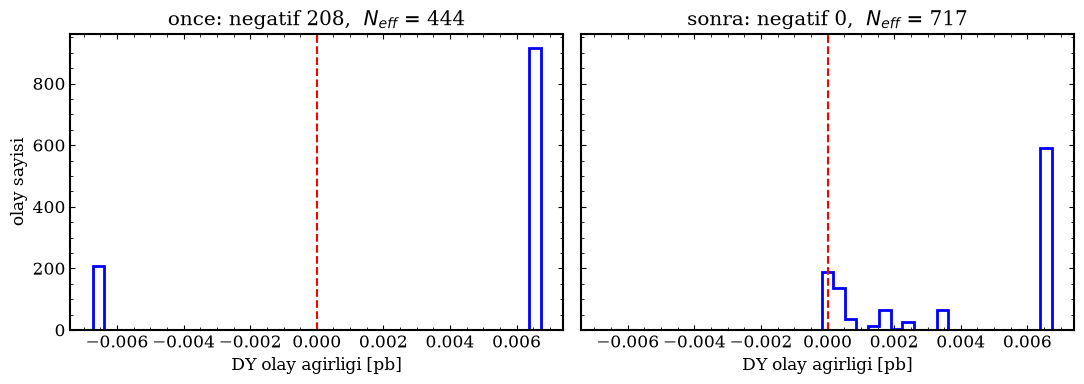

tum arka plan verimi: 11704.82 -> 11704.82  (korunur)
yalniz DY verimi    : 11017.17 -> 10384.62  (surecler arasi kayma)


In [6]:
_ne = lambda w: w.sum()**2 / (w**2).sum() if (w**2).sum() > 0 else 0.
_dy = (bkg.src == 'DY').to_numpy()
_w1 = bkg.weight.to_numpy()

fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
kenar = np.linspace(*np.percentile(_w_once[_dy], [1, 99]), 40)
for a, w, ad in zip(ax, [_w_once[_dy], _w1[_dy]], ['once', 'sonra']):
    a.hist(w, bins=kenar, histtype='step', lw=2, color='blue')
    a.axvline(0, color='red', ls='--')
    a.set_title(f'{ad}: negatif {(w < 0).sum()},  $N_{{eff}}$ = {_ne(w):.0f}')
    a.set_xlabel('DY olay agirligi [pb]')
ax[0].set_ylabel('olay sayisi')
plt.tight_layout()
plt.savefig(OUT + 'yeniden_ornekleme.pdf', bbox_inches='tight')   # sunum icin
plt.show()
# Hucreler surecleri karistirir: DY'nin negatif agirligi komsu
# ZZ/WZ olaylariyla eritilir. Korunan, TUM arka planin toplamidir.
print(f'tum arka plan verimi: {_w_once.sum() * LUMI:.2f} -> '
      f'{_w1.sum() * LUMI:.2f}  (korunur)')
print(f'yalniz DY verimi    : {_w_once[_dy].sum() * LUMI:.2f} -> '
      f'{_w1[_dy].sum() * LUMI:.2f}  (surecler arasi kayma)')

## 1e. Öznitelik envanteri

Sinyal bölgesindeki arka plan olaylarında bulunan sayısal değişkenler listelenir. Öznitelik
olmayan ya da SR'de anlamsız kalan sütunlar (`DISLA`) gerekçeleriyle baştan dışarıda
bırakılır: ağırlıklar ölçüm değildir (`w_gen` DY'yi doğrudan ele verir, yani sızıntıdır);
$n_{\rm jet}\le1$ kesimi nedeniyle ikinci jetle ilgili her değişken sabittir ve `has_jet1`
`n_jets` ile aynı bilgidir.

Her değişken için aralık, kaç farklı değer aldığı ($n$) ve en sık değerin payı gösterilir.
Tür, `tur()` fonksiyonuyla bunlardan belirlenir:

| Tür | Ölçüt | Anlamı |
| --- | --- | --- |
| sabit | $n=1$ | Her olayda aynı; bilgi taşımaz, elenir |
| ayrık | $2\le n\le10$ | Sayım veya evet/hayır (ör. `n_jets`) |
| karışık | en sık değerin payı $>0.2$ | Sürekli, ama bir varsayılan değerde yığılma var (ör. jet yoksa $0$ yazılan jet değişkenleri) |
| sürekli | diğer | Ölçülen büyüklük (ör. `met`, `Z_pt`) |

$n\le10$ ve $0.2$ sınırları tercihtir: sayımlar birkaç değer alır, ölçümler binlerce.
Karışık değişkenlerdeki nokta kütlesi NSF yoğunluğunu ıraksatır (ayrık değişkenlerdeki
sorunun aynısı); bu yüzden §1g'de varsayılan olarak aday dışıdır.

In [7]:
# Oznitelik olmayan ya da SR'de anlamsiz sutunlar, nedenleriyle
DISLA = {
    'weight':        'olay agirligi, olcum degil',
    'w_gen':         'uretici agirligi, olcum degil (DY icin sizinti)',
    'has_jet1':      "SR'de n_jets ile ayni bilgi",
    'jet2_pt':       'n_jets <= 1: ikinci jet yok',
    'jet2_eta':      'n_jets <= 1: ikinci jet yok',
    'dphi_met_jet2': 'n_jets <= 1: ikinci jet yok',
    'has_jet2':      'n_jets <= 1: ikinci jet yok',
}
F = [c for c in bkg.select_dtypes(include='number').columns if c not in DISLA]

ozet = pd.DataFrame({
    'min':                 bkg[F].min(),
    'medyan':              bkg[F].median(),
    'max':                 bkg[F].max(),
    'farkli_deger_sayisi': bkg[F].nunique(),
    'en_sik_deger_payi':   [bkg[f].value_counts(normalize=True).iloc[0] for f in F],
})


# Farkli deger sayisi ve en sik degerin payina gore degisken turu:
#   n = 1                 -> sabit   : her olayda ayni deger, bilgi tasimaz
#   2 <= n <= 10          -> ayrik   : sayim veya evet/hayir (or. n_jets)
#   en sik deger payi>0.2 -> karisik : varsayilan degerde yigilma (jet yoksa 0)
#   diger                 -> surekli : olculen buyukluk (or. met, Z_pt)
def tur(satir):
    if satir.farkli_deger_sayisi == 1:
        return 'SABIT (at)'
    if satir.farkli_deger_sayisi <= 10:
        return 'ayrik'
    if satir.en_sik_deger_payi > 0.2:
        return 'karisik'
    return 'surekli'


ozet['tur'] = ozet.apply(tur, axis=1)

print('disarida birakilanlar:')
for c, neden in DISLA.items():
    print(f'  {c:15s} {neden}')
print(f'\n{len(F)} oznitelik\n')
print(ozet.round(3).to_string())
for t in ('SABIT (at)', 'karisik'):
    print(f'\n{t}:', ozet.index[ozet.tur == t].tolist())

disarida birakilanlar:
  weight          olay agirligi, olcum degil
  w_gen           uretici agirligi, olcum degil (DY icin sizinti)
  has_jet1        SR'de n_jets ile ayni bilgi
  jet2_pt         n_jets <= 1: ikinci jet yok
  jet2_eta        n_jets <= 1: ikinci jet yok
  dphi_met_jet2   n_jets <= 1: ikinci jet yok
  has_jet2        n_jets <= 1: ikinci jet yok

32 oznitelik

                         min   medyan       max  farkli_deger_sayisi  en_sik_deger_payi      tur
met                   50.001   76.363   725.096                 9808              0.000  surekli
met_phi               -3.141   -0.008     3.141                 9812              0.000  surekli
min_dphi_met_jets      0.000    3.142     3.142                 2384              0.757  karisik
dphi_met_jet1          0.000    0.000     3.141                 2384              0.757  karisik
met_over_sqrtHT        0.000    0.000    88.670                 2384              0.757  karisik
hadronic_recoil_pt     0.412   29.500  

## 1f. Değişken dağılımları: sinyal ve arka plan

Sabit olmayan her öznitelik için sinyal (mono-Z) ve arka plan dağılımları birim alana normalize edilerek üst üste çizilir. Eğrilerin ayrıştığı değişkenler ayırt edici öznitelik adaylarıdır. İki arka plan çizgisi vardır:
- **ZZ:** sinyale en çok benzeyen, indirgenemez arka plan,
- **tüm arka plan:** fiziksel verimle ağırlıklı karışım; DY baskın.

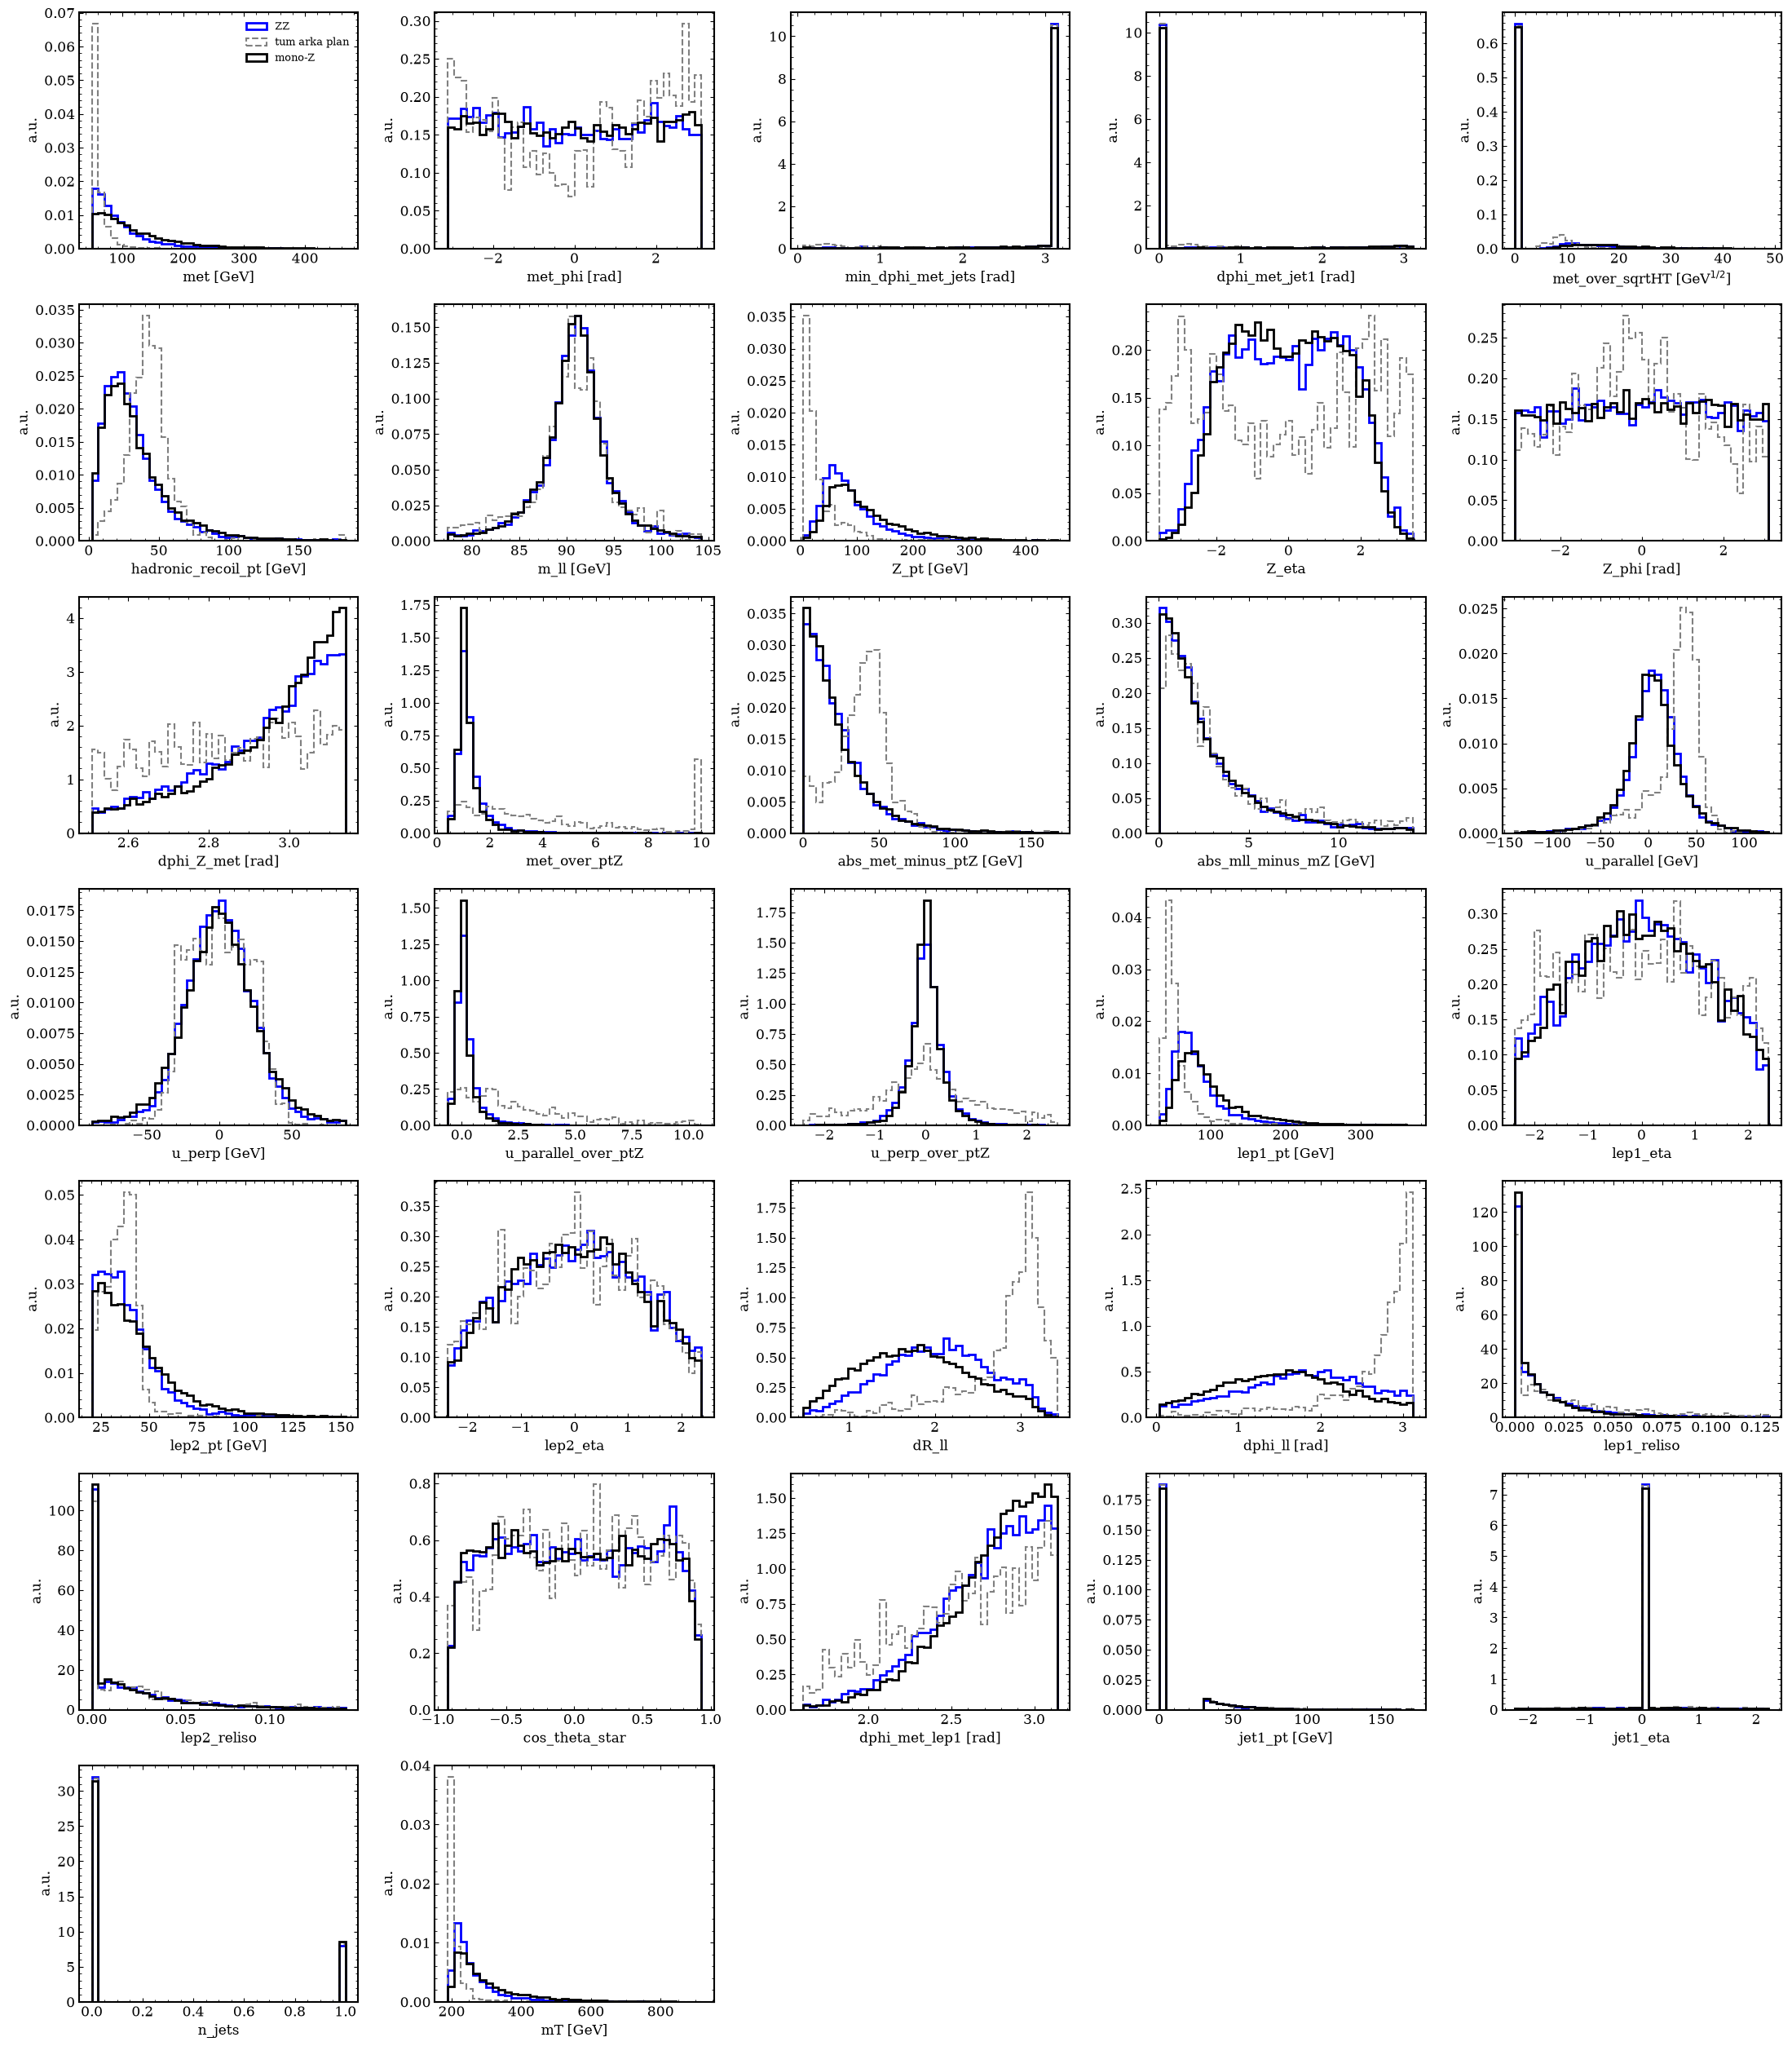

In [8]:
BIRIM = {'met': 'GeV', 'mT': 'GeV', 'Z_pt': 'GeV', 'm_ll': 'GeV',
         'lep1_pt': 'GeV', 'lep2_pt': 'GeV', 'jet1_pt': 'GeV',
         'hadronic_recoil_pt': 'GeV', 'abs_met_minus_ptZ': 'GeV',
         'abs_mll_minus_mZ': 'GeV', 'u_parallel': 'GeV', 'u_perp': 'GeV',
         'met_over_sqrtHT': r'GeV$^{1/2}$', 'dphi_Z_met': 'rad',
         'dphi_ll': 'rad', 'met_phi': 'rad', 'Z_phi': 'rad',
         'dphi_met_lep1': 'rad', 'dphi_met_jet1': 'rad',
         'min_dphi_met_jets': 'rad'}


F_kullan = ozet.index[ozet.tur != 'SABIT (at)'].tolist()
zz_sr = bkg[bkg.src == 'ZZ']

n_sutun = 5
n_satir = int(np.ceil(len(F_kullan) / n_sutun))
fig, ax = plt.subplots(n_satir, n_sutun, figsize=(4.4 * n_sutun, 3.6 * n_satir))

for a, f in zip(ax.flat, F_kullan):
    kenar = np.linspace(*np.percentile(pd.concat([bkg[f], sig[f]]), [0.5, 99.5]), 41)
    a.hist(zz_sr[f], bins=kenar, density=True, histtype='step', lw=2,
           color='blue', label='ZZ')
    a.hist(bkg[f], bins=kenar, weights=bkg.weight, density=True,
           histtype='step', lw=1.5, ls='--', color='gray', label='tum arka plan')
    a.hist(sig[f], bins=kenar, density=True, histtype='step', lw=2,
           color='black', label='mono-Z')
    a.set_xlabel(f'{f} [{BIRIM[f]}]' if f in BIRIM else f)
    a.set_ylabel('a.u.')

ax.flat[0].legend(fontsize=9, frameon=False)
for a in ax.flat[len(F_kullan):]:
    a.axis('off')
plt.tight_layout()
plt.savefig(OUT + 'degisken_dagilimlari.pdf', bbox_inches='tight')   # sunum icin
plt.show()

## 1g. Öznitelik seçimi

Öznitelikler veriden, üç adımda ve **yalnızca eğitim kümesinde** (tohum 0) seçilir; doğrulama
ve test kümeleri bu karara girmez (girseydi sızıntı olurdu):

1. **Ayırt edicilik.** Her adayın tek değişkenli AUC'si iki biçimde hesaplanır: verim
   ağırlıklı (gerçek karışım, DY baskın) ve ağırlıksız (olay sayısı, $ZZ$ baskın). İkisi de
   `AUC_MIN`'in altında kalan aday elenir; iki ana arka plandan birine karşı işe yarayan
   değişken tutulur.
2. **Fazlalık.** Arka plan eğitim olaylarında Spearman korelasyonu hesaplanır. Spearman,
   Pearson'dan farklı olarak her tekdüze (doğrusal olmayan) ilişkiyi yakalar; oran ve açı
   türündeki değişkenler için gereklidir. Ağırlıksızdır, çünkü modeller de sınıf içinde her
   olayı eşit ağırlıkla görür (§4). AUC sırasıyla gidilir; daha önce seçilmiş bir değişkenle
   $|\rho|>$ `RHO_MAX` olan aday elenir (açgözlü fazlalık süzgeci). Böylece her bilgi
   grubundan en ayırt edici temsilci kalır.
3. **Nedensellik.** Korelasyon iki değişkenin birlikte değiştiğini söyler, nedenini söylemez.
   Değişkenlerin çoğu aynı birkaç ölçülen nesneden (iki lepton, $E_T^{\rm miss}$ vektörü,
   jet) **türetildiği** için aralarındaki bağın kaynağı fiziksel tanımdır. Seçilenlerin
   türetilme ilişkileri tablolanır.

Karışık türdeki değişkenler (§1e) varsayılan olarak aday dışıdır: nokta kütlesi NSF
yoğunluğunu ıraksatır ve üç model aynı öznitelikleri kullanmalıdır. Bell ve ark. (2012) da
jet bilgisine dayalı kesim kullanmaz. `KARISIK_DAHIL = True` ile dahil edilebilir.

Literatürden alınan sekizli (`LIT8`) karşılaştırma için tutulur (§6a). Her biri en az iki
bağımsız kaynakta geçer:

| Değişken | Gerekçe | Kaynak |
| --- | --- | --- |
| $E_T^{\rm miss}$ | Mono-$X$ imzasının tanımlayıcı değişkeni | Bell ve ark. (2012); CMS JHEP **03** (2017) 061 |
| $m_T$ | $ZZ\to2\ell2\nu$ için Jacobi kenarı oluşturur, sinyalde oluşmaz | CMS JHEP **03** (2017) 061 |
| $p_T^{Z}$ | Abdallah ve ark. BDT sıralamasında 2. | Abdallah ve ark. (2019), Tablo II |
| $\Delta\phi(Z,E_T^{\rm miss})$ | Sinyalde sırt sırta topoloji | CMS JHEP **03** (2017) 061; Rasineni & Chebrolu |
| $\Delta R(\ell,\ell)$ | Açık kesim; BDT sıralamasında 3. | Bell ve ark. (2012); Abdallah ve ark. (2019) |
| $m_{\ell\ell}$ | $Z$ kütle penceresi | CMS; Rasineni & Chebrolu, Tablo 1 |
| $n_{\rm jet}$ | Jet vetosu ile $t\bar t$/$tW$ bastırma | CMS; Rasineni & Chebrolu |
| $E_T^{\rm miss}/p_T^{Z}$ | Denge değişkeni, sahte $E_T^{\rm miss}$'i bastırır | CMS; Rasineni & Chebrolu, Tablo 8 |

In [9]:
FRAC = 0.2                      # dogrulama ve test paylari -> 60/20/20
LIT8 = ['met', 'mT', 'Z_pt', 'dphi_Z_met',
        'dR_ll', 'm_ll', 'n_jets', 'met_over_ptZ']
KARISIK_DAHIL = False           # varsayilan deger yigilmali degiskenler aday mi?
AUC_MIN = 0.55                  # alti: tek basina neredeyse bilgi tasimiyor
RHO_MAX = 0.80                  # ustu: iki degiskenden yalniz biri tutulur


def split3(df, seed):
    '''Sinif ici 60/20/20 bolunme (stratified).'''
    tr, rest = train_test_split(df, test_size=2 * FRAC, random_state=seed)
    va, te = train_test_split(rest, test_size=0.5, random_state=seed)
    return tr, va, te


b_tr, b_va, b_te = split3(bkg, 0)
s_tr, s_va, s_te = split3(sig, 0)

disla_tur = {'SABIT (at)'} | (set() if KARISIK_DAHIL else {'karisik'})
ADAY = ozet.index[~ozet.tur.isin(disla_tur)].tolist()
y = np.r_[np.zeros(len(b_tr)), np.ones(len(s_tr))]
w = np.r_[b_tr.weight, s_tr.weight]
auc = pd.DataFrame(index=ADAY, columns=['AUC_verim', 'AUC_ham'], dtype=float)
for f in ADAY:
    x = np.r_[b_tr[f], s_tr[f]]
    a_w, a_h = roc_auc_score(y, x, sample_weight=w), roc_auc_score(y, x)
    auc.loc[f] = [max(a_w, 1 - a_w), max(a_h, 1 - a_h)]
auc = auc.sort_values('AUC_verim', ascending=False)
print(f'{len(ADAY)} aday; tur nedeniyle disarida: '
      f'{ozet.index[ozet.tur.isin(disla_tur)].tolist()}\n')
print(auc.round(3).to_string())

25 aday; tur nedeniyle disarida: ['min_dphi_met_jets', 'dphi_met_jet1', 'met_over_sqrtHT', 'lep1_reliso', 'lep2_reliso', 'jet1_pt', 'jet1_eta']

                     AUC_verim  AUC_ham
mT                       0.930    0.668
Z_pt                     0.914    0.658
met                      0.901    0.663
dR_ll                    0.896    0.647
lep1_pt                  0.888    0.656
dphi_ll                  0.876    0.613
met_over_ptZ             0.836    0.571
u_parallel_over_ptZ      0.828    0.565
abs_met_minus_ptZ        0.756    0.542
u_parallel               0.755    0.543
hadronic_recoil_pt       0.687    0.519
dphi_Z_met               0.674    0.565
dphi_met_lep1            0.634    0.556
lep2_pt                  0.590    0.564
abs_mll_minus_mZ         0.555    0.510
cos_theta_star           0.524    0.507
Z_phi                    0.519    0.504
met_phi                  0.516    0.507
u_perp                   0.513    0.505
Z_eta                    0.512    0.506
n_jets         

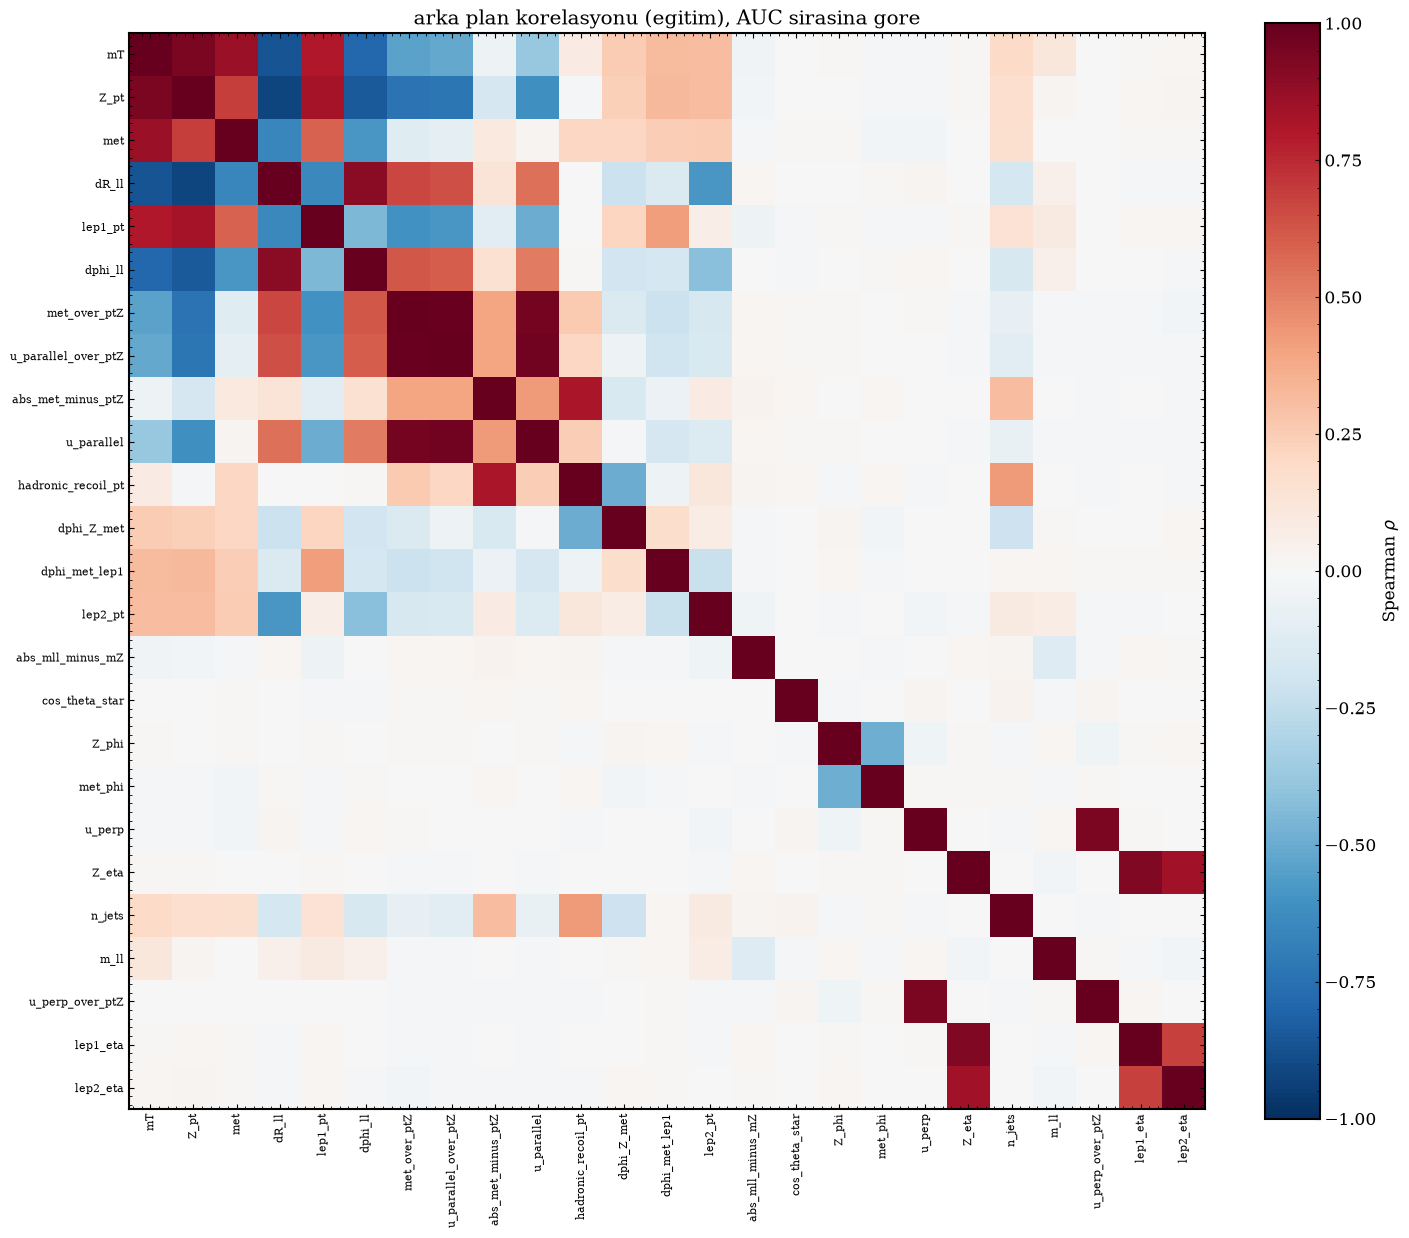

In [10]:
# Butun adaylarin Spearman korelasyonu (arka plan, egitim), AUC sirasinda
R = b_tr[auc.index].corr(method='spearman')
n = len(R)
fig, ax = plt.subplots(figsize=(0.45 * n + 3, 0.45 * n + 2))
im = ax.imshow(R, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(n), R.columns, rotation=90, fontsize=8)
ax.set_yticks(range(n), R.index, fontsize=8)
fig.colorbar(im, ax=ax, fraction=0.046, label=r'Spearman $\rho$')
ax.set_title('arka plan korelasyonu (egitim), AUC sirasina gore')
plt.tight_layout()
plt.savefig(OUT + 'korelasyon_tum.pdf', bbox_inches='tight')   # sunum icin
plt.show()

In [11]:
# Acgozlu fazlalik suzgeci: AUC sirasiyla, zayif ya da secilmis bir
# degiskenle |rho| > RHO_MAX olan aday elenir.
secilen, karar = [], {}
for f in auc.index:
    if auc.loc[f].max() < AUC_MIN:
        karar[f] = f'zayif (AUC <= {auc.loc[f].max():.2f})'
        continue
    benzer = [g for g in secilen if abs(R.loc[f, g]) > RHO_MAX]
    if benzer:
        karar[f] = f'{benzer[0]} ile rho={R.loc[f, benzer[0]]:+.2f}'
        continue
    secilen.append(f)
    karar[f] = 'SECILDI'
print(auc.round(3).assign(karar=pd.Series(karar)).to_string())
auc.assign(karar=pd.Series(karar)).to_csv(OUT + 'oznitelik_secimi.csv')

FEATURES = secilen
import json                         # symbolic/ modulu ayni oznitelikleri kullanir
json.dump(FEATURES, open(OUT + 'features.json', 'w'))
print(f'\nFEATURES ({len(FEATURES)}):', FEATURES)
print('literatur 8lisinde olup secilmeyen:', [f for f in LIT8 if f not in FEATURES])
print('secilip literaturde olmayan       :', [f for f in FEATURES if f not in LIT8])

                     AUC_verim  AUC_ham                            karar
mT                       0.930    0.668                          SECILDI
Z_pt                     0.914    0.658                 mT ile rho=+0.94
met                      0.901    0.663                 mT ile rho=+0.86
dR_ll                    0.896    0.647                 mT ile rho=-0.86
lep1_pt                  0.888    0.656                 mT ile rho=+0.80
dphi_ll                  0.876    0.613                          SECILDI
met_over_ptZ             0.836    0.571                          SECILDI
u_parallel_over_ptZ      0.828    0.565       met_over_ptZ ile rho=+0.99
abs_met_minus_ptZ        0.756    0.542                          SECILDI
u_parallel               0.755    0.543       met_over_ptZ ile rho=+0.96
hadronic_recoil_pt       0.687    0.519  abs_met_minus_ptZ ile rho=+0.81
dphi_Z_met               0.674    0.565                          SECILDI
dphi_met_lep1            0.634    0.556            

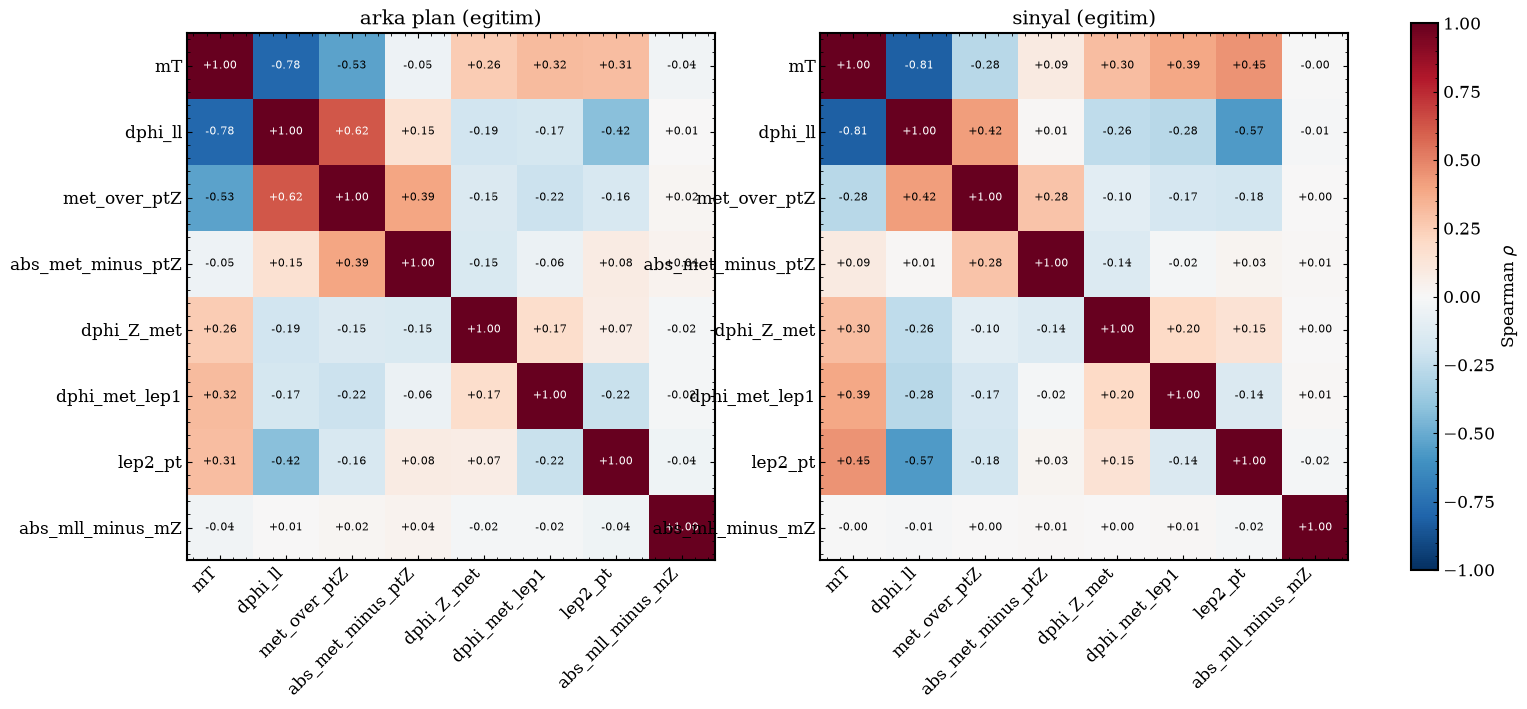

secilenler arasi en buyuk |rho|: arka plan 0.78, sinyal 0.81  (sinir 0.8)


In [12]:
# Secilenlerin korelasyonu: arka plan ve sinyal yan yana. Iki matris
# arasindaki fark da ayirt edici bilgidir (tek degiskenli AUC bunu goremez).
R_b = b_tr[FEATURES].corr(method='spearman')
R_s = s_tr[FEATURES].corr(method='spearman')
n = len(FEATURES)
fig, ax = plt.subplots(1, 2, figsize=(2 * (0.7 * n + 2.5), 0.7 * n + 1.5))
for a, R_, baslik in zip(ax, [R_b, R_s], ['arka plan', 'sinyal']):
    im = a.imshow(R_, cmap='RdBu_r', vmin=-1, vmax=1)
    a.set_xticks(range(n), FEATURES, rotation=45, ha='right')
    a.set_yticks(range(n), FEATURES)
    for i in range(n):
        for j in range(n):
            a.text(j, i, f'{R_.iloc[i, j]:+.2f}', ha='center', va='center',
                   fontsize=8,
                   color='white' if abs(R_.iloc[i, j]) > 0.6 else 'black')
    a.set_title(f'{baslik} (egitim)')
fig.colorbar(im, ax=ax, fraction=0.025, label=r'Spearman $\rho$')
plt.savefig(OUT + 'korelasyon_secilen.pdf', bbox_inches='tight')   # sunum icin
plt.show()

ust = np.triu(np.ones((n, n), bool), k=1)
print(f'secilenler arasi en buyuk |rho|: '
      f'arka plan {R_b.abs().where(ust).max().max():.2f}, '
      f'sinyal {R_s.abs().where(ust).max().max():.2f}  (sinir {RHO_MAX})')

In [13]:
# Nedensellik: korelasyonun kaynagi olan turetilme iliskileri. Fiziksel
# tanimlara gore yazilmistir; kesin formuller _extract.py icindedir.
TURETILME = {
    'Z_pt': ['lep1', 'lep2'], 'Z_eta': ['lep1', 'lep2'], 'Z_phi': ['lep1', 'lep2'],
    'm_ll': ['lep1', 'lep2'], 'dR_ll': ['lep1', 'lep2'],
    'dphi_ll': ['lep1', 'lep2'], 'cos_theta_star': ['lep1', 'lep2'],
    'abs_mll_minus_mZ': ['m_ll'],
    'dphi_Z_met': ['Z_phi', 'met_phi'],
    'met_over_ptZ': ['met', 'Z_pt'], 'abs_met_minus_ptZ': ['met', 'Z_pt'],
    'mT': ['met', 'Z_pt', 'dphi_Z_met', 'm_ll'],
    'hadronic_recoil_pt': ['met', 'Z_pt'],
    'u_parallel': ['met', 'Z_pt'], 'u_perp': ['met', 'Z_pt'],
    'u_parallel_over_ptZ': ['u_parallel', 'Z_pt'],
    'u_perp_over_ptZ': ['u_perp', 'Z_pt'],
    'met_over_sqrtHT': ['met', 'jet1'], 'dphi_met_lep1': ['met_phi', 'lep1'],
    'min_dphi_met_jets': ['met_phi', 'jet1'], 'dphi_met_jet1': ['met_phi', 'jet1'],
}
tablo_n = pd.DataFrame(
    [{'oznitelik': f,
      'kaynaklari': ', '.join(TURETILME.get(f, ['(dogrudan olcum)'])),
      'kaynagi da secili': ', '.join(k for k in TURETILME.get(f, [])
                                     if k in FEATURES) or '-'}
     for f in FEATURES]).set_index('oznitelik')
print(tablo_n.to_string())
tablo_n.to_csv(OUT + 'turetilme.csv')

                                    kaynaklari kaynagi da secili
oznitelik                                                       
mT                 met, Z_pt, dphi_Z_met, m_ll        dphi_Z_met
dphi_ll                             lep1, lep2                 -
met_over_ptZ                         met, Z_pt                 -
abs_met_minus_ptZ                    met, Z_pt                 -
dphi_Z_met                      Z_phi, met_phi                 -
dphi_met_lep1                    met_phi, lep1                 -
lep2_pt                       (dogrudan olcum)                 -
abs_mll_minus_mZ                          m_ll                 -


`kaynağı da seçili` sütunu doluysa öznitelik ile kaynağı birlikte listededir. Bu bir hata
değildir: korelasyonları `RHO_MAX`'ın altında kaldığı için türetilmiş değişken (ör. `mT`)
kaynaklarını doğrusal olmayan biçimde birleştirir ve ek bilgi taşır. Ama aynı ölçümden
geldikleri için permütasyon öneminde (§6d) birbirinin yerini kısmen doldurabilirler.

## 2. Değerlendirme ölçütleri

**Terim ayrımı.** Türkçede iki ayrı nicelik için de "verim" kullanılabildiğinden
bu defterde ikisi ayrılır:

| terim | tanım |
| --- | --- |
| *yield* | $\sigma\mathcal{L}$ ile normalize edilmiş beklenen olay sayısı ($S$, $B$) |
|*efficiency* | bir kesmeden geçen olay oranı ($\varepsilon_S$, $\varepsilon_B$) |


**İki ayrı ROC hesaplanır ve ikisi de raporlanır.**

*Ham (ağırlıksız) ROC* her olayı eşit sayar; saf makine öğrenmesi ayırma
gücüdür. *Verim ağırlıklı ROC* ise olayları fiziksel ağırlıklarıyla sayar,
yani arka planın gerçek bileşimini yansıtır.

Bu kanalda ikisi **çok farklıdır** ve fark bir kusur değil, ölçülen bir
olgudur: sinyal bölgesinde arka plan olaylarının çoğunluğu $ZZ$'dir, ama $ZZ$
verimin küçük bir kısmını oluşturur; DY için tersi geçerlidir (paylar §1c bileşim
tablosundadır). Dolayısıyla ağırlıksız AUC fiilen
$ZZ$'ye karşı başarıyı ölçer -- ki $ZZ\to\ell\ell\nu\nu$ sinyalle
kinematik olarak neredeyse özdeş, **indirgenemez** bir arka plandır.

Her iki ROC'tan türetilen anlamlılık iyileştirme eğrisi:

$$\mathrm{SIC}(t)=\frac{\varepsilon_S(t)}{\sqrt{\varepsilon_B(t)}}$$

**Fizik düzeyi.** Asimov anlamlılığı, kesit ve ışınlılıkla normalize edilmiş
verimler üzerinden:

$$Z_A=\sqrt{2\left[(S+B)\ln\!\left(1+\frac{S}{B}\right)-S\right]}$$

İki biçimde raporlanır:

1. **Tek kesim.** Doğrulama kümesinde seçilen tek bir eşiğin üstündeki
   $S$ ve $B$. Basit ama eşiğin üstündeki her şeyi tek sayıya indirger,
   yani dağılımın *şeklini* atar.
2. **Binlenmiş şekil uyumu.** Skor ekseni bölünür ve bin başına
   anlamlılıklar birleştirilir:

$$Z_{\rm şekil}=\sqrt{\textstyle\sum_i Z_{A,i}^2}
\;\xrightarrow[\;S\ll B\;]{}\;
\sqrt{\textstyle\sum_i S_i^2/B_i}$$

Bu, binlenmiş Poisson olabilirliğinin asimptotik karşılığıdır ve HEP'te
standart olan şekil uyumuna denk gelir. Tanım gereği tek kesimden küçük
olamaz. Bin kenarları da **doğrulama** kümesinde belirlenir ve her bin
$N_{\rm eff}\ge10$ etkin arka plan olayı taşır, yani hiçbir bin birkaç
ağır olaya dayanmaz. Sistematik yok, binler bağımsız varsayılır.

**Negatif ağırlıklar.** DY `amcatnloFXFX` ile üretildiği için olayların
$\%16.5$'i negatif üretici ağırlığı taşır ve negatif kütle geçerli bir
olasılık ölçüsü tanımlamaz. Ağırlıklar mutlak değere çevrilmez; bunun yerine
hücre yeniden örneklemesi uygulanır: negatif ağırlıklı her olay, faz
uzayındaki komşularıyla toplamı pozitif olana dek bir hücre oluşturur ve
ağırlık hücre içinde eşit paylaştırılır. Negatif ağırlıklı olay sayısının
sıfıra indiği ve toplam verimin korunduğu §1d'de gösterilir. Bu nedenle verim ağırlıklı ROC burada **tanımlıdır**.

Arka plan verimi istatistiksel olarak anlamsız hâle gelmesin diye her çalışma
noktasında Kish etkin örneklem büyüklüğü sınırlanır:

$$N_{\rm eff}=\frac{\left(\sum_i w_i\right)^2}{\sum_i w_i^2}\ \ge\ 10$$

*Kaynak:* G. Cowan ve ark., Eur. Phys. J. C **71** (2011) 1554 (denk. 97);
L. Kish, *Survey Sampling* (1965); S. Andersen, D. Maître, Eur. Phys. J. C
**82** (2022) 433.

In [14]:
NEFF_MIN = 10.0
GRID = np.logspace(-4, 0, 300)      # ortak yanlis pozitif orani izgarasi


def n_eff(weights):
    """Kish etkin orneklem buyuklugu."""
    sq = (weights ** 2).sum()
    return weights.sum() ** 2 / sq if sq > 0 else 0.0


def asimov(s, b):
    """Asimov anlamliligi; tanimsiz bolgede sifir."""
    if s <= 0 or b <= 0:
        return 0.0
    return np.sqrt(2 * ((s + b) * np.log1p(s / b) - s))


def pick_cut(score_bkg, score_sig, w_bkg, w_sig, scale):
    """DOGRULAMA kumesinde Z_A'yi maksimize eden esigi secer.

    Esik yalnizca burada belirlenir. Test kumesi hicbir asamada
    optimizasyona girmez, yalnizca secilmis esikte raporlanir.
    """
    cut, best = np.nan, np.nan
    for t in np.quantile(score_bkg, np.linspace(0.5, 0.9995, 80)):
        w_sel = w_bkg[score_bkg > t]
        b = w_sel.sum() * LUMI * scale
        s = w_sig[score_sig > t].sum() * LUMI * scale
        if s <= 0 or b <= 0 or n_eff(w_sel) < NEFF_MIN:
            continue
        z = asimov(s, b)
        if np.isnan(best) or z > best:
            cut, best = t, z
    return cut


def apply_cut(cut, score_bkg, score_sig, w_bkg, w_sig, scale):
    """Sabit esikte TEST kumesindeki verimler ve anlamlilik."""
    bos = dict(S=np.nan, B=np.nan, Neff=np.nan, epsS=np.nan, epsB=np.nan)
    if np.isnan(cut):
        return bos, np.nan
    kb, ks = score_bkg > cut, score_sig > cut
    w_sel = w_bkg[kb]
    b = w_sel.sum() * LUMI * scale
    s = w_sig[ks].sum() * LUMI * scale
    ne = n_eff(w_sel)
    out = dict(S=s, B=b, Neff=ne, epsS=ks.mean(), epsB=kb.mean())
    return out, (asimov(s, b) if ne >= NEFF_MIN else np.nan)


def shape_edges(score_bkg, w_bkg, neff_min=NEFF_MIN, max_bins=20):
    """Sekil uyumu icin YUKARIDAN ASAGIYA bin kenarlari.

    neff_bins (cizim icin yazilmisti) dusuk uctan baslar ve max_bins'e
    ulasinca kalan butun yuksek-skor bolgesini TEK bine yigar -- oysa
    ayrim tam orada kurulur. Olculdu: boyle kurulan ust bin optimum
    kesimin cok altindan basliyor (0.015 vs 0.163) ve sinyali arka planla
    seyreltiyordu. Burada tersi yapilir: en yuksek skordan asagi inilir,
    her bin N_eff >= neff_min olunca kapanir, yani sinyal bolgesi ince
    binlenir ve kaba binler sadece bos kuyrukta kalir.
    """
    o = np.argsort(score_bkg)[::-1]
    xs, ws = np.asarray(score_bkg)[o], np.asarray(w_bkg)[o]
    ust = xs[0] + abs(xs[0]) * 1e-9 + 1e-9
    kenar, bas = [ust], 0
    for i in range(1, len(xs) + 1):
        p = ws[bas:i]
        q = (p ** 2).sum()
        if q > 0 and p.sum() ** 2 / q >= neff_min and len(kenar) < max_bins:
            kenar.append(xs[i - 1])
            bas = i
    kenar.append(xs[-1] - abs(xs[-1]) * 1e-9 - 1e-9)
    return np.array(kenar[::-1])


def binned_asimov(edges, score_bkg, score_sig, w_bkg, w_sig, scale):
    """Binlenmis sekil uyumu:  Z = sqrt( sum_i Z_i^2 ).

    Tek bir kesim, esigin ustundeki butun olaylari tek bir sayiya indirger
    ve dagilimin SEKLINI atar. Binlenmis Poisson olabilirliginin asimptotik
    karsiligi, bin basina Asimov anlamliliklarinin kareler toplamidir;
    S << B limitinde sum_i S_i^2 / B_i olur (Cowan ve ark. 2011).

    Kenarlar DOGRULAMA kumesinde her bin N_eff ~ NEFF_MIN olacak sekilde
    kuruldugu icin, bagimsiz TEST kumesinde binlerin bir kismi esigin
    altina duser. Bunlari ATMAK sinyali de atar ve sekil uyumunu tek
    kesimin ALTINA dusurur; bu yuzden yetersiz binler yuksek skordan
    baslayarak komsusuyla BIRLESTIRILIR. Birlestirme limitte tek kesime
    indirgenir, dolayisiyla sonuc kesimden kotu olamaz.
    """
    ib = np.clip(np.digitize(score_bkg, edges) - 1, 0, len(edges) - 2)
    isg = np.clip(np.digitize(score_sig, edges) - 1, 0, len(edges) - 2)
    gruplar, birikim = [], []
    for k in range(len(edges) - 2, -1, -1):      # yuksek skordan asagiya
        birikim.append(k)
        wb = w_bkg[np.isin(ib, birikim)]
        if wb.sum() > 0 and n_eff(wb) >= NEFF_MIN:
            gruplar.append(list(birikim))
            birikim = []
    if birikim and gruplar:
        gruplar[-1].extend(birikim)              # artani son gruba kat
    z2 = 0.0
    for g in gruplar:
        wb = w_bkg[np.isin(ib, g)]
        b = wb.sum() * LUMI * scale
        s = w_sig[np.isin(isg, g)].sum() * LUMI * scale
        if s <= 0 or b <= 0 or n_eff(wb) < NEFF_MIN:
            continue
        z2 += asimov(s, b) ** 2
    return np.sqrt(z2)


def roc_on_grid(score_bkg, score_sig, w_bkg=None, w_sig=None):
    """ROC'u ortak izgaraya tasir; (eps_S, SIC) dondurur.

    Agirlik verilirse verim-agirlikli ROC hesaplanir. Hucre yeniden
    ornekleme sonrasi tum agirliklar negatif olmadigindan bu gecerlidir.
    """
    truth = np.r_[np.zeros(len(score_bkg)), np.ones(len(score_sig))]
    sw = None if w_bkg is None else np.r_[w_bkg, w_sig]
    fpr, tpr, _ = roc_curve(truth, np.r_[score_bkg, score_sig],
                            sample_weight=sw)
    eps_s = np.interp(GRID, fpr, tpr)
    return eps_s, eps_s / np.sqrt(GRID)

## 2b. Bell ve ark. (2012) ile tutarlılık: kesim tabanlı referans

N. F. Bell, J. B. Dent, A. J. Galea, T. D. Jacques, L. M. Krauss, T. J. Weiler,
*Searching for Dark Matter at the LHC with a Mono-Z*, Phys. Rev. D **86** (2012) 096011,
arXiv:1209.0231. Makale mono-$Z$ kanalını önerir ve olay seçimini (§III B) şöyle kurar:

| Kesim | Bell ve ark. | Bu defterin SR'si (§1c) |
| --- | --- | --- |
| $Z$ kütle penceresi | $\lvert m_{\ell\ell}-m_Z\rvert<30$ GeV (60 GeV pencere) | `load` ön seçimi (aralık aşağıda yazdırılır) |
| öncü lepton $p_T$ | $>50$ GeV (en az bir müon) | `load` ön seçimi |
| $E_T^{\rm miss}$ | $>150$ GeV | $\ge50$ GeV |
| $\Delta R(\ell\ell)$ | $0.5<\Delta R<1$ (hızlı $Z$'nin leptonları dar açılı) | yok |
| jet | kesim yok | $n_{\rm jet}\le1$ |
| $\Delta\phi(Z,E_T^{\rm miss})$ | yok | $>2.5$ |

Bu defterin SR'si bilinçli olarak daha gevşektir; ayrımı makine öğrenmesi yapar. Makalenin
kesimleri SR'nin üstüne uygulanarak **kesim tabanlı bir referans** $Z_A$ elde edilir. Üç
modelin $Z_A$'sı (§5a) bu referansın üzerinde olmalıdır; değilse modeller basit kesimlerin
ötesinde bilgi kullanmıyor demektir. Makaleye göre kesimlerden sonra kalan arka plana
$Z\nu\bar\nu$ (burada $ZZ\to2\ell2\nu$) hâkim olmalıdır; kesim akışındaki süreç dökümü bunu
sınar (döküm, süreçleri karıştırmamak için yeniden örnekleme öncesi ağırlıklarla yapılır).

**MC istatistiği gerekliliği.** Makale, $Z$+jet dışındaki her süreç için beklenen olay
sayısının en az 4 katı, $Z$+jet için yaklaşık 1.3 katı simüle edilmiş olay kullanır (§V).
Burada oran etkin olay sayısıyla ölçülür, $N_{\rm eff}/N_{\rm beklenen}$; ağırlıklar eşitse
bu $1/(w\,\mathcal{L})$'ye indirgenir. DY, makaledeki $Z$+jet'in karşılığıdır. Sağlanmayan
süreçlerde $Z_A$'nın MC istatistik belirsizliği büyüktür; çalışma noktalarındaki
$N_{\rm eff}\ge10$ koşulu bu yüzden vardır.

**Farklar.** Makale $\sqrt s=7,8,14$ TeV, yalnızca $\mu\mu$ kanalı, dedektör simülasyonu
olmadan (yalnız $Z$+jet için Delphes) ve renkli bir skaler $\eta$ aracılığıyla kuarklara
bağlanan Majorana $\chi$ modeli kullanır. Bu defter $\sqrt s=13$ TeV'de tam CMS simülasyonu
ve CMS basitleştirilmiş modelleriyle çalışır. Bu yüzden mutlak verimler değil, **seçimin
mantığı** karşılaştırılır. Lepton tadı seçimi `_extract.py`'nin ön seçimindedir.

In [15]:
# MC istatistigi (Bell ve ark. §V): N_eff / N_beklenen, yeniden orneklemeden once
GEREKLI = {'DY': 1.3}            # Z+jet karsiligi; digerleri >= 4
satir = []
for k, d in {**parcalar, 'sinyal': sig}.items():
    w0 = d.weight.to_numpy()
    beklenen = w0.sum() * LUMI
    oran = n_eff(w0) / beklenen if beklenen > 0 else np.nan
    esik = GEREKLI.get(k, 4.0)
    satir.append({'surec': k, 'N_MC': len(d), 'N_eff': n_eff(w0),
                  'N_beklenen': beklenen, 'N_eff/N_beklenen': oran,
                  'gerekli': esik, 'saglaniyor': bool(oran >= esik)})
mc_ist = pd.DataFrame(satir).set_index('surec')
mc_ist.to_csv(OUT + 'mc_istatistigi.csv')
print(mc_ist.round(3).to_string())
print('\nsaglanmayan:', mc_ist.index[~mc_ist.saglaniyor].tolist())

             N_MC      N_eff  N_beklenen  N_eff/N_beklenen  gerekli  saglaniyor
surec                                                                          
DY           1122    444.239   11017.170             0.040      1.3       False
ZZ           7016   7016.000     145.764            48.132      4.0        True
WZ           1486   1486.000     148.591            10.001      4.0        True
ttbar         102    102.000     322.762             0.316      4.0       False
tW_top         44     44.000      36.820             1.195      4.0       False
tW_antitop     42     42.000      33.714             1.246      4.0       False
sinyal      13097  13097.000      96.017           136.403      4.0        True

saglanmayan: ['DY', 'ttbar', 'tW_top', 'tW_antitop']


In [16]:
# Bell ve ark. kesimleri, SR'nin ustune birikimli. S, B, N_eff ve Z_A yeniden
# ornekleme sonrasi agirliklarla (modellerle ayni); surec dokumu oncesiyle.
BELL = [('SR (1c)',                  lambda d: np.ones(len(d), bool)),
        ('|m_ll - m_Z| < 30 GeV',    lambda d: (d.m_ll - MZ).abs() < 30),
        ('oncu lepton p_T > 50 GeV', lambda d: d.lep1_pt > 50),
        ('MET > 150 GeV',            lambda d: d.met > 150),
        ('0.5 < dR_ll < 1',          lambda d: (d.dR_ll > 0.5) & (d.dR_ll < 1))]

print(f'SR icinde m_ll: {bkg.m_ll.min():.1f}-{bkg.m_ll.max():.1f} GeV, '
      f'oncu lepton p_T >= {bkg.lep1_pt.min():.1f} GeV\n')
src = bkg.src.to_numpy()
mb, ms = np.ones(len(bkg), bool), np.ones(len(sig), bool)
akis = []
for ad, kesim in BELL:
    mb &= np.asarray(kesim(bkg))
    ms &= np.asarray(kesim(sig))
    wb = bkg.weight.to_numpy()[mb]
    S, B, ne = sig.weight.to_numpy()[ms].sum() * LUMI, wb.sum() * LUMI, n_eff(wb)
    r = {'kesim': ad, 'S': S, 'B': B, 'N_eff(B)': ne,
         'Z_A': asimov(S, B) if ne >= NEFF_MIN else np.nan}
    for p in parcalar:
        r[f'B_{p}'] = _w_once[mb & (src == p)].sum() * LUMI
    akis.append(r)
bell = pd.DataFrame(akis).set_index('kesim')
bell.to_csv(OUT + 'bell_kesim_akisi.csv')
print(bell.round(3).to_string())

Z_REF = bell.Z_A.iloc[-1]                 # butun kesimler
_gecerli = bell.Z_A.dropna()              # N_eff >= NEFF_MIN olan en siki kesim
Z_REF_GECERLI = ((_gecerli.index[-1], _gecerli.iloc[-1]) if len(_gecerli)
                 else ('yok', np.nan))
print(f'\nkesim tabanli referans Z_A (butun kesimler) = {Z_REF:.2f}')
print(f'N_eff >= {NEFF_MIN:.0f} olan en siki kesim: "{Z_REF_GECERLI[0]}", '
      f'Z_A = {Z_REF_GECERLI[1]:.2f}')

SR icinde m_ll: 76.1-105.9 GeV, oncu lepton p_T >= 25.0 GeV

                               S          B  N_eff(B)    Z_A       B_DY     B_ZZ     B_WZ  B_ttbar  B_tW_top  B_tW_antitop
kesim                                                                                                                     
SR (1c)                   96.017  11704.822   900.294  0.886  11017.170  145.764  148.591  322.762    36.820        33.714
|m_ll - m_Z| < 30 GeV     96.017  11704.822   900.294  0.886  11017.170  145.764  148.591  322.762    36.820        33.714
oncu lepton p_T > 50 GeV  91.251   4813.814   411.300  1.311   4244.575  130.785  127.593  240.489    25.105        31.306
MET > 150 GeV             24.721     36.080    95.873  3.744      0.000   18.574   11.899    3.164     0.837         1.605
0.5 < dR_ll < 1           10.440     12.269   215.497  2.661      0.000    6.669    5.600    0.000     0.000         0.000

kesim tabanli referans Z_A (butun kesimler) = 2.66
N_eff >= 10 olan en siki k

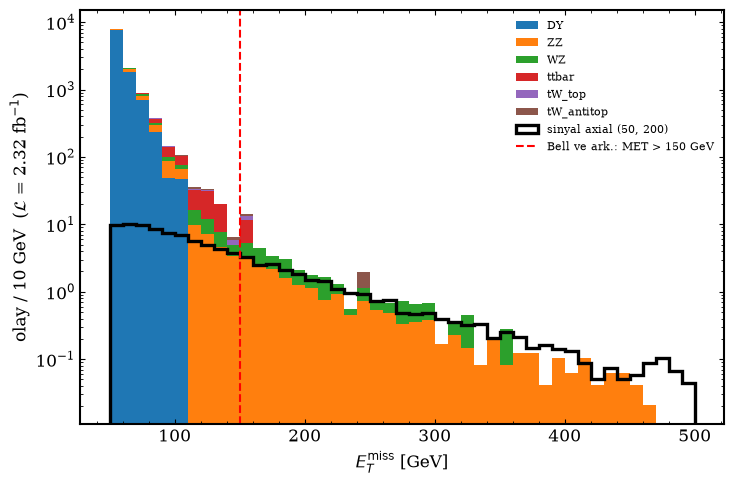

In [17]:
# Bell ve ark. Sekil 2/9 benzeri: SR'de MET, surec bazinda yiginli, 10 GeV bin.
# Log olcekte negatif bin olusmasin diye yeniden ornekleme sonrasi agirliklar.
kenar = np.arange(50, 510, 10)
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.hist([bkg.met[bkg.src == p] for p in parcalar], bins=kenar, stacked=True,
        weights=[bkg.weight[bkg.src == p] * LUMI for p in parcalar],
        label=list(parcalar))
ax.hist(sig.met, bins=kenar, weights=sig.weight * LUMI, histtype='step',
        lw=2.4, color='black', label=f'sinyal {SINYAL}')
ax.axvline(150, color='red', ls='--', label='Bell ve ark.: MET > 150 GeV')
ax.set_yscale('log')
ax.set_xlabel(r'$E_T^{\rm miss}$ [GeV]')
ax.set_ylabel(r'olay / 10 GeV  ($\mathcal{L}$ = 2.32 fb$^{-1}$)')
ax.legend(fontsize=8, frameon=False)
plt.tight_layout()
plt.savefig(OUT + 'bell_met.pdf', bbox_inches='tight')   # sunum icin
plt.show()

## 3. Üç model

Hiperparametreler bilinçli olarak sade ve literatürdeki temel kurulumlarla
uyumludur; amaç en iyi ayarı aramak değil, üç yaklaşımı eşit koşulda
karşılaştırmaktır. Kapsamlı hiperparametre taraması yapılmamıştır.

**BDT.** Gradyan artırmalı karar ağaçları, HEP'te TMVA ve XGBoost ile kurulan
standart kurulumdur. Burada `HistGradientBoostingClassifier` kullanılır: aynı
histogram tabanlı gradyan artırma algoritması (LightGBM soyundan), ek bağımlılık
gerektirmez. Ağaç toplulukları gradyan tabanlı sinir ağları olmadığından torch
ile kurulmaz; bu, literatürdeki yerleşik uygulamanın gereğidir.

**DNN.** PyTorch ile iki gizli katmanlı (128 birim, ReLU, dropout 0.1) tam
bağlı sınıflandırıcı; `BCEWithLogitsLoss`, Adam, erken durdurma. Çıktı
$\tanh(z/2)=2\hat p-1$ olarak verilir; bu, log-oranın tek-yönlü monoton bir
dönüşümüdür, dolayısıyla sıralama olabilirlik oranının sıralamasıdır.

**NSF.** Rasyonel kuadratik spline akışları (`zuko.flows.NSF`, 8 dönüşüm,
8 bin, 256$\times$2 bağlam ağı). İki ayrı yoğunluk öğrenilir ve skor
$\log p(x\mid S)-\log p(x\mid B)$ olarak kurulur. Ayrık `n_jets` değişkeni
eğitimde dequantize edilir: her olaya bir jetlik aralıkta düzgün gürültü eklenir
($x\to x+u$, $u\sim U[-\tfrac12,\tfrac12]$ jet). Girdiler ölçeklendiği için bu aralık
ölçeklenmiş uzayda $1/\sigma_{n_{\rm jet}}$ genişliğindedir (`jet_sutunu`). Doğrulama
kaybı da aynı biçimde, sabit tohumla dequantize edilmiş olaylarda ölçülür. Aksi halde sürekli
yoğunluk ayrık noktalarda ıraksar. `n_jets` seçilmemişse dequantize uygulanmaz. Jacobian katkıları zuko'nun
`log_prob` çağrısında tam olarak hesaba katılır.

Her model aynı `StandardScaler` ile ölçeklenir ve ölçekleyici **yalnızca eğitim
kümesinde** uydurulur.

*Kaynak:* T. Chen, C. Guestrin, KDD '16, 785 (XGBoost); C. Durkan ve ark.,
NeurIPS **32** (2019) 7511 (Neural Spline Flows); A. Rogozhnikov ve ark.
(HEP'te BDT uygulamalari).

In [18]:
def fit_bdt(x_tr, y_tr, w_tr, x_va, y_va, w_va, seed,
            step=25, max_iter=600, patience=4):
    """Gradyan artirmali agaclar; agac sayisi DOGRULAMA kaybiyla secilir.

    sklearn'un kendi erken durdurmasi egitim kumesinden rastgele bir dilim
    ayirir; burada bunun yerine acikca ayrilmis dogrulama kumesi kullanilir,
    boylece uc model de ayni kumede durdurulur.
    """
    probe = HistGradientBoostingClassifier(
        max_depth=4, learning_rate=0.08, early_stopping=False,
        warm_start=True, max_iter=step, random_state=seed)
    best, best_n, waited = np.inf, step, 0
    for n in range(step, max_iter + 1, step):
        probe.max_iter = n
        probe.fit(x_tr, y_tr, sample_weight=w_tr)
        loss = log_loss(y_va, probe.predict_proba(x_va)[:, 1],
                        sample_weight=w_va)
        if loss < best - 1e-5:
            best, best_n, waited = loss, n, 0
        else:
            waited += 1
            if waited >= patience:
                break
    model = HistGradientBoostingClassifier(
        max_depth=4, learning_rate=0.08, early_stopping=False,
        max_iter=best_n, random_state=seed)
    model.fit(x_tr, y_tr, sample_weight=w_tr)
    return (lambda x: 2 * model.predict_proba(x)[:, 1] - 1), best_n


class Mlp(nn.Module):
    """Iki gizli katmanli sinif olasiligi kestiricisi."""

    def __init__(self, n_features, width=128, p_drop=0.1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_features, width), nn.ReLU(), nn.Dropout(p_drop),
            nn.Linear(width, width), nn.ReLU(), nn.Dropout(p_drop),
            nn.Linear(width, 1))

    def forward(self, x):
        return self.net(x).squeeze(-1)


def fit_dnn(x_tr, y_tr, w_tr, x_va, y_va, w_va, seed,
            epochs=200, patience=20):
    """Capraz entropi ile egitilen MLP; durdurma dogrulama kumesinde."""
    torch.manual_seed(seed)
    tt = lambda a: torch.tensor(a, dtype=torch.float32, device=DEVICE)
    x, y, w = tt(x_tr), tt(y_tr), tt(w_tr)
    xv, yv, wv = tt(x_va), tt(y_va), tt(w_va)
    model = Mlp(x.shape[1]).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
    loss_fn = nn.BCEWithLogitsLoss(reduction='none')
    best_loss, best_state, waited = np.inf, None, 0
    for _ in range(epochs):
        model.train()
        perm = torch.randperm(len(x), device=DEVICE)
        for i in range(0, len(perm), 1024):
            j = perm[i:i + 1024]
            loss = (loss_fn(model(x[j]), y[j]) * w[j]).sum() / w[j].sum()
            opt.zero_grad()
            loss.backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            v = ((loss_fn(model(xv), yv) * wv).sum() / wv.sum()).item()
        if v < best_loss:
            best_loss, waited = v, 0
            best_state = {k: t.clone() for k, t in model.state_dict().items()}
        else:
            waited += 1
            if waited >= patience:
                break
    model.load_state_dict(best_state)
    model.eval()

    @torch.no_grad()
    def score(x_new):
        t = torch.tensor(x_new, dtype=torch.float32, device=DEVICE)
        return torch.tanh(model(t) / 2).cpu().numpy()

    return score


def fit_flow(x_train, x_valid, seed, jet_col=None, jet_adim=1.0,
             epochs=200, patience=20):
    """Tek bir yogunlugu ogrenen rasyonel kuadratik spline akisi."""
    torch.manual_seed(seed)
    flow = zuko.flows.NSF(features=x_train.shape[1], context=0, transforms=8,
                          bins=8, hidden_features=[256, 256]).to(DEVICE)
    opt = torch.optim.Adam(flow.parameters(), lr=3e-4, weight_decay=1e-5)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs,
                                                       eta_min=1e-6)
    x = torch.tensor(x_train, dtype=torch.float32, device=DEVICE)
    xv = torch.tensor(x_valid, dtype=torch.float32, device=DEVICE)
    if jet_col is not None:                    # dogrulama da ayni yogunlukta
        g = torch.Generator().manual_seed(seed)
        xv[:, jet_col] += ((torch.rand(len(xv), generator=g) - 0.5)
                           * jet_adim).to(DEVICE)
    best_loss, best_state, waited = np.inf, None, 0
    for _ in range(epochs):
        flow.train()
        perm = torch.randperm(len(x), device=DEVICE)
        for i in range(0, len(perm), 2048):
            batch = x[perm[i:i + 2048]].clone()
            if jet_col is not None:            # ayrik degiskeni dequantize et
                batch[:, jet_col] += ((torch.rand_like(batch[:, jet_col]) - 0.5)
                                      * jet_adim)
            loss = -flow().log_prob(batch).mean()
            opt.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(flow.parameters(), 1.0)
            opt.step()
        sched.step()
        flow.eval()
        with torch.no_grad():
            v = -flow().log_prob(xv).mean().item()
        if v < best_loss:
            best_loss, waited = v, 0
            best_state = {k: t.clone() for k, t in flow.state_dict().items()}
        else:
            waited += 1
            if waited >= patience:
                break
    flow.load_state_dict(best_state)
    flow.eval()
    return flow


def jet_sutunu(F, scaler):
    """n_jets'in sutunu ve olceklenmis uzayda bir jetlik adim; yoksa (None, 1)."""
    if 'n_jets' not in F:
        return None, 1.0
    j = F.index('n_jets')
    return j, 1.0 / scaler.scale_[j]


@torch.no_grad()
def log_prob(flow, x_new, chunk=8192):
    """Yogunlugu parcalar halinde degerlendirir."""
    t = torch.tensor(x_new, dtype=torch.float32, device=DEVICE)
    return np.concatenate([flow().log_prob(t[i:i + chunk]).cpu().numpy()
                           for i in range(0, len(t), chunk)])

## 4. Adil karşılaştırma protokolü

**Bölünme.** Her tohumda sinyal ve arka plan *ayrı ayrı* %60 eğitim / %20
doğrulama / %20 test olarak bölünür. İki sınıf kendi içinde bölündüğü için
sınıf oranları üç kümede de korunur (stratified split).

**Her kümenin tek bir görevi var:**

| küme | kullanım |
| --- | --- |
| eğitim (%60) | model parametreleri |
| doğrulama (%20) | erken durdurma **ve** $Z_A$ eşiğinin seçimi |
| test (%20) | yalnızca raporlama |

**Sızıntıya karşı iki önlem.** (i) Ölçekleyici yalnızca eğitim kümesinde
uydurulur. (ii) $Z_A$'yı maksimize eden eşik **doğrulama** kümesinde seçilir
ve test kümesinde *sabit* olarak uygulanır. Eşiği doğrudan test kümesinde
aramak, test kümesiyle model seçmek anlamına gelir ve anlamlılığı yukarı
yanlı kestirir.

**Erken durdurma üçünde de aynı kümede.** BDT'de ağaç sayısı doğrulama
log-kaybıyla seçilir (scikit-learn'ün kendi iç bölünmesi devre dışı);
DNN'de doğrulama çapraz entropisi; NSF'de doğrulama negatif
log-olabilirliği izlenir.

**Ağırlıkların ayrımı.** Eğitimde yalnızca sınıf dengeleyici ağırlık
$w_i = \tfrac12/N_{\rm sınıf}$ kullanılır; fiziksel kesit ağırlıkları
*yalnızca* verim ve anlamlılık hesabına girer. İki ağırlık hiçbir yerde
karıştırılmaz.

Beş bağımsız bölünme (tohum 0--4) koşulur; belirsizlikler bu beş ölçümün
standart sapmasıdır.

In [19]:
MODELS = ('BDT', 'DNN', 'NSF')     # FRAC ve split3 §1g'de tanimli


def evaluate_split(seed):
    """Bir bolunmede uc modeli kurar; olcutleri ve egrileri dondurur."""
    b_tr, b_va, b_te = split3(bkg, seed)
    s_tr, s_va, s_te = split3(sig, seed)
    scaler = StandardScaler().fit(b_tr[FEATURES])     # yalnizca egitimde
    tf = lambda d: scaler.transform(d[FEATURES])
    jet_col, jet_adim = jet_sutunu(FEATURES, scaler)

    def xyw(bd, sd):
        """Sinif dengeli egitim/dogrulama girdisi (fizik agirligi degil)."""
        x = np.vstack([tf(bd), tf(sd)])
        y = np.r_[np.zeros(len(bd)), np.ones(len(sd))]
        w = np.r_[np.full(len(bd), 0.5 / len(bd)),
                  np.full(len(sd), 0.5 / len(sd))]
        return x, y, w

    x_tr, y_tr, w_tr = xyw(b_tr, s_tr)
    x_va, y_va, w_va = xyw(b_va, s_va)

    bdt_score, n_tree = fit_bdt(x_tr, y_tr, w_tr, x_va, y_va, w_va, seed)
    scorers = {'BDT': bdt_score,
               'DNN': fit_dnn(x_tr, y_tr, w_tr, x_va, y_va, w_va, seed)}
    flow_sm = fit_flow(tf(b_tr), tf(b_va), seed, jet_col, jet_adim)
    flow_dm = fit_flow(tf(s_tr), tf(s_va), seed, jet_col, jet_adim)
    scorers['NSF'] = lambda x: log_prob(flow_dm, x) - log_prob(flow_sm, x)

    row, curves = {'seed': seed, 'n_tree_BDT': n_tree}, {}
    wb_va, ws_va = b_va.weight.to_numpy(), s_va.weight.to_numpy()
    wb_te, ws_te = b_te.weight.to_numpy(), s_te.weight.to_numpy()
    for name in MODELS:
        f = scorers[name]
        sb_tr, ss_tr = f(tf(b_tr)), f(tf(s_tr))
        sb_va, ss_va = f(tf(b_va)), f(tf(s_va))
        sb, ss = f(tf(b_te)), f(tf(s_te))

        cut = pick_cut(sb_va, ss_va, wb_va, ws_va, 1 / FRAC)   # dogrulamada
        nokta, za = apply_cut(cut, sb, ss, wb_te, ws_te, 1 / FRAC)  # testte
        # Sekil uyumu: bin kenarlari da dogrulamada belirlenir.
        kenar = shape_edges(sb_va, wb_va, max_bins=20)
        za_bin = binned_asimov(kenar, sb, ss, wb_te, ws_te, 1 / FRAC)

        truth = np.r_[np.zeros(len(sb)), np.ones(len(ss))]
        eps_s, sic = roc_on_grid(sb, ss)
        eps_w, sic_w = roc_on_grid(sb, ss, wb_te, ws_te)
        row[f'auc_{name}'] = roc_auc_score(truth, np.r_[sb, ss])
        row[f'aucw_{name}'] = roc_auc_score(truth, np.r_[sb, ss],
                                            sample_weight=np.r_[wb_te, ws_te])
        row[f'auctr_{name}'] = roc_auc_score(
            np.r_[np.zeros(len(sb_tr)), np.ones(len(ss_tr))],
            np.r_[sb_tr, ss_tr])
        row[f'sic_{name}'] = sic.max()
        row[f'sicw_{name}'] = sic_w.max()
        row[f'rej_{name}'] = 1 / np.interp(0.5, eps_w, GRID)
        row[f'cut_{name}'], row[f'Za_{name}'] = cut, za
        row[f'Zabin_{name}'], row[f'nbin_{name}'] = za_bin, len(kenar) - 1
        for k, v in nokta.items():
            row[f'{k}_{name}'] = v
        curves[name] = {'eps_s': eps_s, 'sic': sic, 'eps_s_w': eps_w,
                        'sic_w': sic_w, 'sb': sb, 'ss': ss, 'cut': cut}
    return row, curves, (wb_te, ws_te, b_te['src'].to_numpy())


rows, curves_all = [], []
for seed in range(5):
    row, curves, test_w = evaluate_split(seed)
    rows.append(row)
    curves_all.append(curves)
    print(f'  tohum {seed} ({row["n_tree_BDT"]:3d} agac): ' + '  '.join(
        f'{m} AUC={row[f"aucw_{m}"]:.3f} Za={row[f"Za_{m}"]:.2f}'
        f'/{row[f"Zabin_{m}"]:.2f}' for m in MODELS), flush=True)

results = pd.DataFrame(rows)
results.to_csv(OUT + 'seed_results.csv', index=False)

  tohum 0 (100 agac): BDT AUC=0.940 Za=3.85/4.44  DNN AUC=0.930 Za=4.33/4.70  NSF AUC=0.883 Za=1.63/1.90
  tohum 1 ( 50 agac): BDT AUC=0.936 Za=nan/4.35  DNN AUC=0.936 Za=4.26/4.81  NSF AUC=0.869 Za=1.48/2.48
  tohum 2 ( 50 agac): BDT AUC=0.942 Za=4.34/5.08  DNN AUC=0.942 Za=4.84/4.97  NSF AUC=0.832 Za=1.41/1.63
  tohum 3 ( 50 agac): BDT AUC=0.942 Za=4.26/4.78  DNN AUC=0.939 Za=3.99/5.20  NSF AUC=0.906 Za=1.63/1.94
  tohum 4 ( 50 agac): BDT AUC=0.944 Za=4.56/4.92  DNN AUC=0.941 Za=4.13/4.96  NSF AUC=0.880 Za=1.72/2.04


## 5a. Sayısal sonuçlar

Üç ölçüt ayrı şeyler söyler ve bilinçli olarak birlikte raporlanır:

- **AUC (verim)** — fiziksel arka plan karışımında sıralama gücü.
- **AUC (ham)** ve **eğitim$-$test farkı** — saf sınıflandırma başarısı ve
  aşırı öğrenme kontrolü. Fark $\gtrsim 0.02$ ise model eğitim kümesini
  ezberlemeye başlamıştır.
- **$1/\varepsilon_B$** — $\varepsilon_S = 0.5$'te arka plan baskılama.
- **$Z_A$** — doğrulama kümesinde seçilen sabit eşikte, test kümesindeki
  anlamlılık. Öncelik budur: yüksek AUC değil, güvenilir anlamlılık.
  Kesim tabanlı referansla (Bell ve ark. kesimleri, §2b) karşılaştırılır.

In [20]:
summary = pd.DataFrame(
    {'AUC_verim': [results[f'aucw_{m}'].mean() for m in MODELS],
     'AUC_ham': [results[f'auc_{m}'].mean() for m in MODELS],
     'AUC_egitim': [results[f'auctr_{m}'].mean() for m in MODELS],
     'asiri_ogrenme': [(results[f'auctr_{m}'] - results[f'auc_{m}']).mean()
                       for m in MODELS],
     'SIC_verim': [results[f'sicw_{m}'].mean() for m in MODELS],
     'SIC_ham': [results[f'sic_{m}'].mean() for m in MODELS],
     'rej_at_eps_S_0.5': [results[f'rej_{m}'].mean() for m in MODELS],
     'Z_A_kesim': [results[f'Za_{m}'].mean() for m in MODELS],
     'Z_A_kesim_sd': [results[f'Za_{m}'].std() for m in MODELS],
     'Z_A_sekil': [results[f'Zabin_{m}'].mean() for m in MODELS],
     'Z_A_sekil_sd': [results[f'Zabin_{m}'].std() for m in MODELS],
     'n_bin': [results[f'nbin_{m}'].mean() for m in MODELS]},
    index=list(MODELS)).round(3)
summary.to_csv(OUT + 'model_comparison.csv')
print(summary.to_string())
print(f'\nBDT agac sayisi (dogrulamada secildi): '
      f'{results["n_tree_BDT"].tolist()}')
kazanc = [results[f'Zabin_{m}'].mean() / results[f'Za_{m}'].mean()
          for m in MODELS]
print('sekil uyumunun kesime gore kazanci: ' +
      ', '.join(f'{m} {k:.2f}x' for m, k in zip(MODELS, kazanc)))
print(f'kesim tabanli referans (Bell ve ark., §2b; tum orneklem): '
      f'butun kesimler Z_A = {Z_REF:.2f}, gecerli en siki kesim '
      f'"{Z_REF_GECERLI[0]}" Z_A = {Z_REF_GECERLI[1]:.2f}')
gecersiz = int(results[[f'Za_{m}' for m in MODELS]].isna().sum().sum())
if gecersiz:
    print(f'uyari: {gecersiz} olcumde N_eff >= {NEFF_MIN:.0f} kosulunu '
          'saglayan calisma noktasi bulunamadi (NaN)')

     AUC_verim  AUC_ham  AUC_egitim  asiri_ogrenme  SIC_verim  SIC_ham  rej_at_eps_S_0.5  Z_A_kesim  Z_A_kesim_sd  Z_A_sekil  Z_A_sekil_sd  n_bin
BDT      0.941    0.681       0.713          0.033      5.476    1.067            79.985      4.252         0.297      4.713         0.313   20.0
DNN      0.938    0.681       0.699          0.018      5.762    1.066            69.584      4.307         0.322      4.926         0.187   20.0
NSF      0.874    0.610       0.706          0.096      2.242    1.030            13.821      1.574         0.125      1.999         0.310   19.6

BDT agac sayisi (dogrulamada secildi): [100, 50, 50, 50, 50]
sekil uyumunun kesime gore kazanci: BDT 1.11x, DNN 1.14x, NSF 1.27x
kesim tabanli referans (Bell ve ark., §2b; tum orneklem): butun kesimler Z_A = 2.66, gecerli en siki kesim "0.5 < dR_ll < 1" Z_A = 2.66
uyari: 1 olcumde N_eff >= 10 kosulunu saglayan calisma noktasi bulunamadi (NaN)


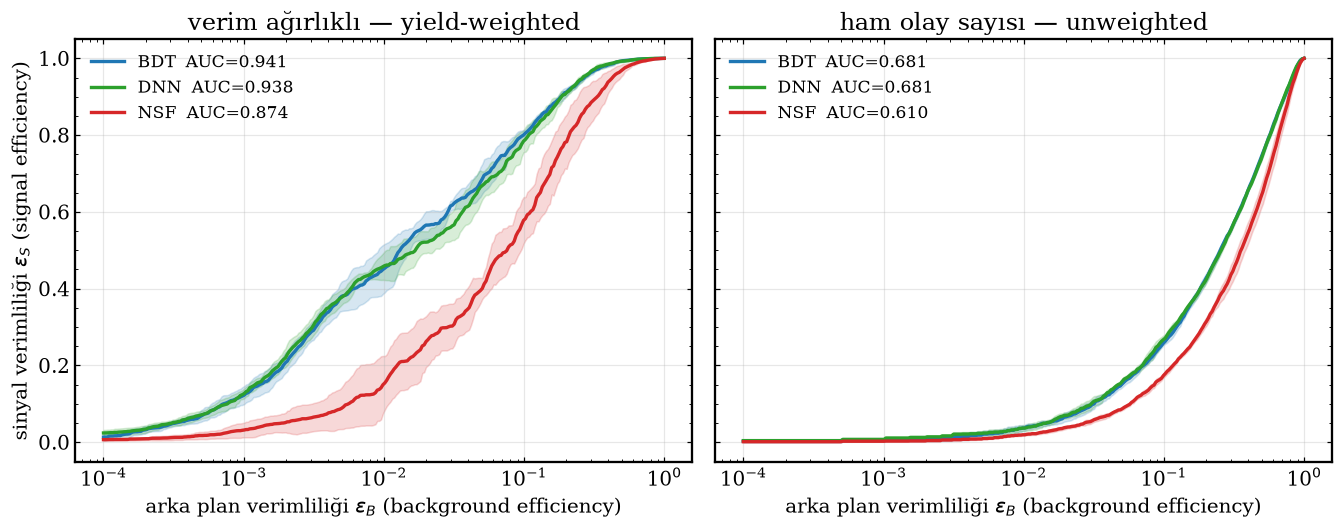

In [21]:
import matplotlib.pyplot as plt

plt.rcParams.update({'font.size': 13, 'figure.dpi': 110})
COLOR = {'BDT': '#1f77b4', 'DNN': '#2ca02c', 'NSF': '#d62728'}


def band(ax, key, ylabel, etiket):
    """Bes bolunmenin ortalamasi ve +-1 sigma bandi."""
    for m in MODELS:
        y = np.array([c[m][key] for c in curves_all])
        mu, sd = y.mean(0), y.std(0)
        ax.plot(GRID, mu, color=COLOR[m], lw=2.2, label=f'{m}  {etiket(m)}')
        ax.fill_between(GRID, mu - sd, mu + sd, color=COLOR[m], alpha=0.18)
    ax.set_xscale('log')
    ax.set_xlabel(r'arka plan verimliliği $\varepsilon_B$'
                  ' (background efficiency)')
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.3)
    ax.legend(frameon=False, fontsize=11)


# Sekil 1 -- ROC: verim agirlikli (fizik) ve ham (saf ML ayirma)
fig, ax = plt.subplots(1, 2, figsize=(12.4, 5), sharey=True)
band(ax[0], 'eps_s_w',
     r'sinyal verimliliği $\varepsilon_S$ (signal efficiency)',
     lambda m: f'AUC={summary.loc[m, "AUC_verim"]:.3f}')
ax[0].set_title('verim ağırlıklı — yield-weighted')
band(ax[1], 'eps_s', '', lambda m: f'AUC={summary.loc[m, "AUC_ham"]:.3f}')
ax[1].set_title('ham olay sayısı — unweighted')
fig.tight_layout()
fig.savefig(OUT + 'roc_comparison.pdf')
plt.show()

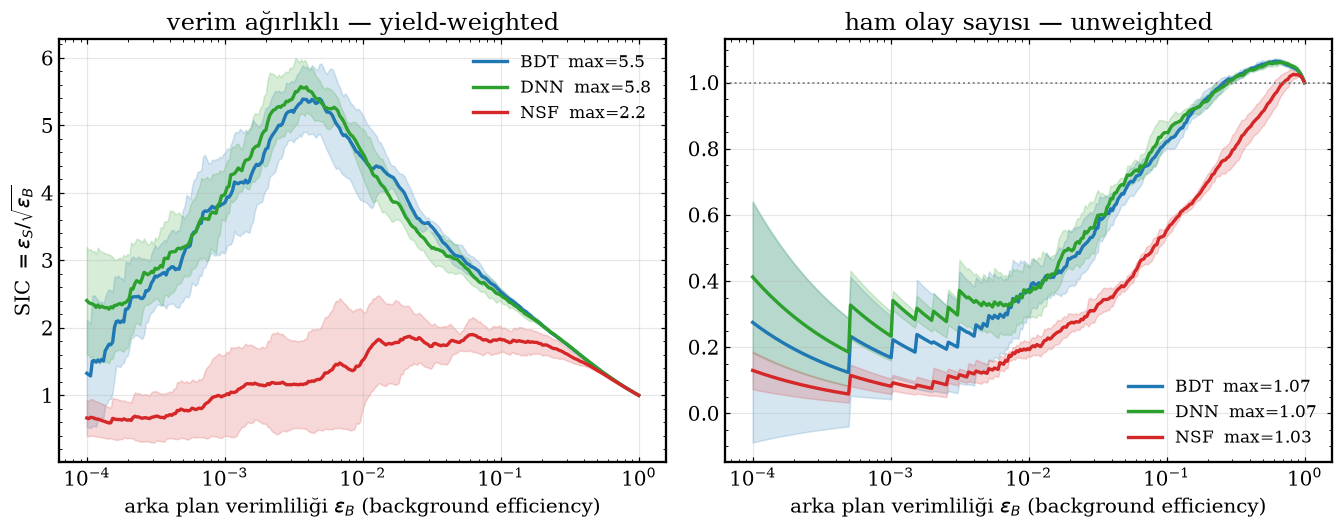

In [22]:
# Sekil 2 -- SIC
fig, ax = plt.subplots(1, 2, figsize=(12.4, 5))
band(ax[0], 'sic_w', r'SIC $=\varepsilon_S/\sqrt{\varepsilon_B}$',
     lambda m: f'max={summary.loc[m, "SIC_verim"]:.1f}')
ax[0].set_title('verim ağırlıklı — yield-weighted')
band(ax[1], 'sic', '',
     lambda m: f'max={summary.loc[m, "SIC_ham"]:.2f}')
ax[1].set_title('ham olay sayısı — unweighted')
ax[1].axhline(1.0, color='gray', ls=':', lw=1.2)
fig.tight_layout()
fig.savefig(OUT + 'sic_comparison.pdf')
plt.show()

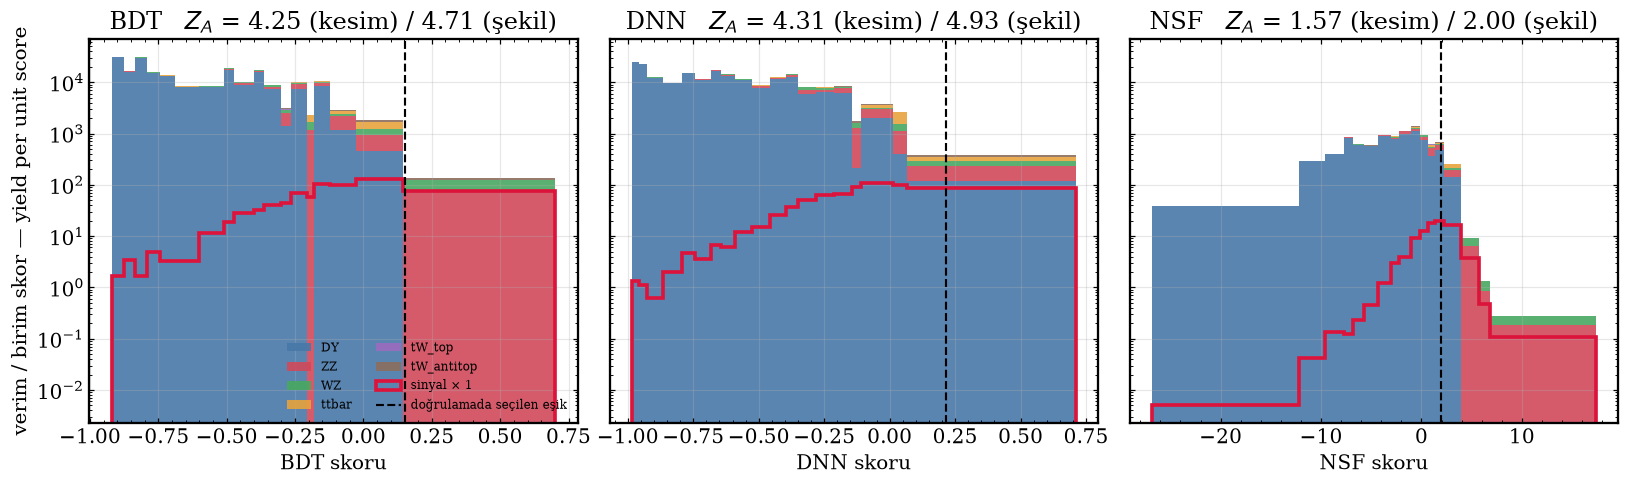

In [23]:
# Sekil 3 -- skor dagilimlari, surec bazinda yiginli
# Degisken genislikli binlerde hist() bin basina TOPLAM cizer; genis bir bin
# otomatik yuksek gorunur. Agirligi bin genisligine bolup birim skor basina
# verim cizilir, boylece binler karsilastirilabilir olur.
def per_width(x, w, edges):
    """Agirligi dustugu binin genisligine boler."""
    i = np.clip(np.digitize(x, edges) - 1, 0, len(edges) - 2)
    return w / np.diff(edges)[i]


def display_bins(x, w, neff_min=10.0, max_bins=25):
    """Gosterim icin N_eff-uyarlamali binleme, TABAN genislikli.

    neff_bins yalnizca etkin olay sayisina bakar; skorun yerel yogun
    oldugu bir bolgede (ornegin karar esigine yakin) birkac agir DY
    olayi birbirine cok yakin dusup kilcal genislikte bir bin olusturabilir.
    Toplam agirlik kucuk olsa da "birim skor basina verim" bu dar bine
    bolununce yapay bir sivri uc ortaya cikar -- istatistiksel olarak
    gecerli ama gorsel olarak yaniltici. Taban genislik bunu onler.
    """
    edges = neff_bins(x, w, neff_min=neff_min, max_bins=max_bins)
    floor = (x.max() - x.min()) / max_bins / 2.5
    k = [edges[0]]
    for e in edges[1:]:
        if e - k[-1] >= floor or e == edges[-1]:
            k.append(e)
    return np.array(k)


PROC = ['DY', 'ZZ', 'WZ', 'ttbar', 'tW_top', 'tW_antitop']
PROC_RENK = ['#4878a8', '#d1495b', '#48a860', '#e8a33d', '#9b6bbf', '#8c6d5c']
w_b, w_s, src_b = test_w
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharey=True)
for ax, m in zip(axes, MODELS):
    c = curves_all[-1][m]
    sb, ss = c['sb'], c['ss']
    edges = display_bins(sb, w_b, neff_min=10.0, max_bins=25)
    ax.hist([sb[src_b == p] for p in PROC], bins=edges, stacked=True,
            color=PROC_RENK, label=PROC, alpha=0.9,
            weights=[per_width(sb[src_b == p], w_b[src_b == p] * LUMI / FRAC,
                               edges) for p in PROC])
    ax.hist(ss, bins=edges, histtype='step', color='crimson', lw=2.4,
            weights=per_width(ss, w_s * LUMI / FRAC, edges),
            label=r'sinyal $\times$ 1')
    ax.axvline(c['cut'], color='k', ls='--', lw=1.4,
               label='doğrulamada seçilen eşik')
    ax.set_yscale('log')
    ax.set_xlabel(f'{m} skoru')
    ax.set_title(f'{m}   $Z_A$ = {summary.loc[m, "Z_A_kesim"]:.2f}'
                 f' (kesim) / {summary.loc[m, "Z_A_sekil"]:.2f} (şekil)')
    ax.grid(alpha=0.3)
axes[0].set_ylabel(r'verim / birim skor — yield per unit score')
axes[0].legend(fontsize=8, ncol=2, frameon=False)
fig.tight_layout()
fig.savefig(OUT + 'score_distributions.pdf')
plt.show()

## 5b. Çalışma noktası ve karışıklık matrisi

Her model, **doğrulama kümesinde** seçilmiş kendi eşiğinde değerlendirilir;
aşağıdaki sayıların tamamı **test kümesinden** gelir. Karışıklık matrisi ham
olay sayılarını, altındaki tablo ise aynı noktadaki fiziksel verimleri
($S$, $B$) gösterir. İkisi bilinçli olarak yan yanadır: olay sayısı ile verim
bu kanalda orantılı değildir, çünkü bir DY olayı bir $ZZ$ olayından yüzlerce
kat daha ağırdır (§1a).

*Kaynak:* bu çalışma; $Z_A$ tanımı G. Cowan ve ark., EPJC **71** (2011) 1554.

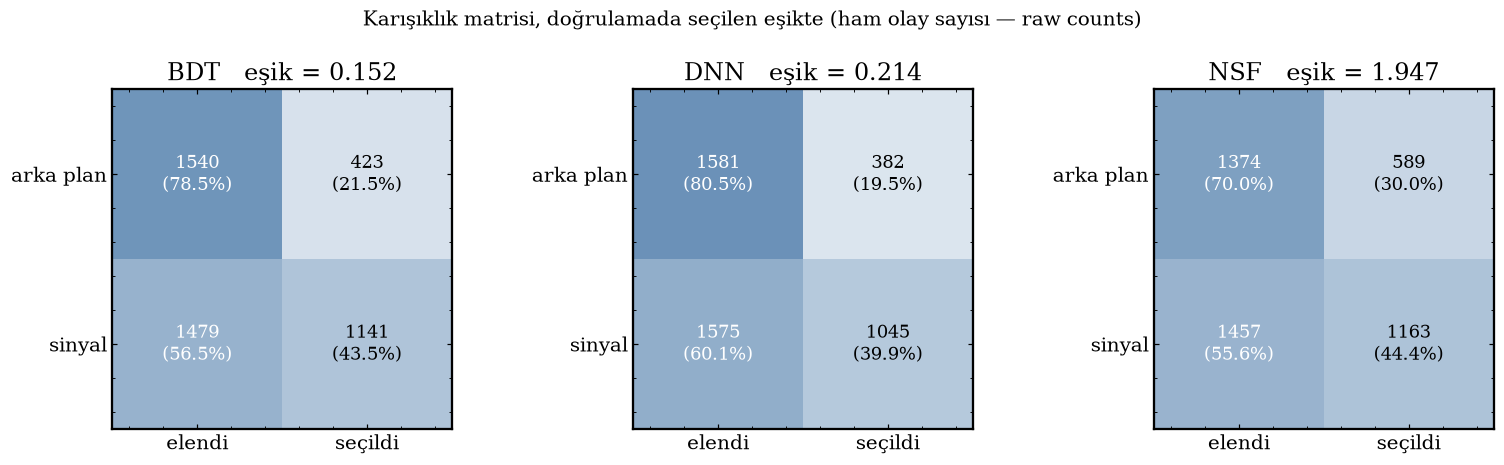

        esik  eps_S  eps_B       S        B    N_eff    Z_A
model                                                      
BDT    0.152  0.435  0.215  41.824   71.167  141.184  4.563
DNN    0.214  0.399  0.195  38.306   74.101   20.626  4.131
NSF    1.947  0.444  0.300  42.631  602.740   13.964  1.717


In [24]:
from matplotlib.colors import LinearSegmentedColormap

CMAP = LinearSegmentedColormap.from_list('mz', ['#ffffff', '#4878a8'])
fig, axes = plt.subplots(1, 3, figsize=(14.4, 4.3))
satirlar = []
son = results.iloc[-1]
for ax, m in zip(axes, MODELS):
    c = curves_all[-1][m]
    sb, ss, cut = c['sb'], c['ss'], c['cut']
    cm = np.array([[(sb <= cut).sum(), (sb > cut).sum()],
                   [(ss <= cut).sum(), (ss > cut).sum()]], float)
    oran = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(oran, cmap=CMAP, vmin=0, vmax=1)
    for a in range(2):
        for b in range(2):
            ax.text(b, a, f'{int(cm[a, b])}\n({oran[a, b]:.1%})',
                    ha='center', va='center', fontsize=12,
                    color='white' if oran[a, b] > 0.55 else 'black')
    ax.set_xticks([0, 1], ['elendi', 'seçildi'])
    ax.set_yticks([0, 1], ['arka plan', 'sinyal'])
    ax.set_title(f'{m}   eşik = {cut:.3f}')
    satirlar.append({'model': m, 'esik': cut, 'eps_S': son[f'epsS_{m}'],
                     'eps_B': son[f'epsB_{m}'], 'S': son[f'S_{m}'],
                     'B': son[f'B_{m}'], 'N_eff': son[f'Neff_{m}'],
                     'Z_A': son[f'Za_{m}']})
fig.suptitle('Karışıklık matrisi, doğrulamada seçilen eşikte '
             '(ham olay sayısı — raw counts)', fontsize=13)
fig.tight_layout()
fig.savefig(OUT + 'confusion_matrix.pdf')
plt.show()

nokta = pd.DataFrame(satirlar).set_index('model').round(3)
nokta.to_csv(OUT + 'working_point.csv')
print(nokta.to_string())

## 5c. Ağırlıksız AUC neden düşük görünüyor?

Toplam ağırlıksız AUC (§5a tablosunda `AUC_ham`), arka planı oluşturan süreçlerin olay-sayısı ağırlıklı ortalamasıdır. Son bölünmenin BDT skorları, test kümesindeki her sürece ayrı ayrı uygulanarak bu toplamın nereden geldiği gösterilir.

In [25]:
w_b, w_s, src_b = test_w
sb_last = curves_all[-1]['BDT']['sb']
ss_last = curves_all[-1]['BDT']['ss']
yt_last = np.r_[np.zeros(len(sb_last)), np.ones(len(ss_last))]

bilesen = []
for p in sorted(set(src_b)):
    m = src_b == p
    if m.sum() < 30:
        continue
    y_p = np.r_[np.zeros(m.sum()), np.ones(len(ss_last))]
    auc_p = roc_auc_score(y_p, np.r_[sb_last[m], ss_last])
    bilesen.append({'surec': p, 'olay_payi': m.mean(), 'auc': auc_p})
bilesen = pd.DataFrame(bilesen).sort_values('olay_payi', ascending=False)
bilesen.to_csv(OUT + 'bilesen_auc.csv', index=False)
print(bilesen.round(3).to_string(index=False))

surec  olay_payi   auc
   ZZ      0.709 0.627
   WZ      0.161 0.719
   DY      0.108 0.948


## 6a. Kaç öznitelik gerekli?

Ana karşılaştırma §1g'de veriden seçilen kümeyi kullanır. Burada aynı protokol (60/20/20,
eşik doğrulamada, aynı fit fonksiyonları) beş öznitelik kümesiyle tekrarlanır: elle seçilmiş
4'lü, tanı amaçlı 9'lu, literatür 8'lisi (`LIT8`), §1g seçimi ve referans analizin tam havuzu
(sabit ve sızıntılı sütunlar hariç). Havuz karışık türdeki jet değişkenlerini de içerir; NSF
sonucu bu yüzden temkinli okunmalıdır. Amaç en iyi kümeyi test kümesinden seçmek değil (bu
sızıntı olurdu), seçimin literatür 8'lisinden ve boyut artırmaktan ne kadar etkilendiğini
ölçmektir.

In [26]:
F36 = ['met', 'met_phi', 'min_dphi_met_jets', 'dphi_met_jet1',
       'dphi_met_jet2', 'met_over_sqrtHT', 'hadronic_recoil_pt', 'm_ll',
       'Z_pt', 'Z_eta', 'Z_phi', 'dphi_Z_met', 'met_over_ptZ',
       'abs_met_minus_ptZ', 'abs_mll_minus_mZ', 'u_parallel', 'u_perp',
       'u_parallel_over_ptZ', 'u_perp_over_ptZ', 'lep1_pt', 'lep1_eta',
       'lep2_pt', 'lep2_eta', 'dR_ll', 'dphi_ll', 'lep1_reliso',
       'lep2_reliso', 'cos_theta_star', 'dphi_met_lep1', 'jet1_pt',
       'jet1_eta', 'jet2_pt', 'jet2_eta', 'has_jet1', 'has_jet2', 'n_jets']
POOL = [f for f in F36 if f not in DISLA and bkg[f].std() > 1e-9]
FEATURE_SETS = {
    'elle 4D': ['met', 'mT', 'dphi_Z_met', 'n_jets'],
    'tani 9D': ['met', 'mT', 'Z_pt', 'Z_eta', 'dphi_Z_met', 'dR_ll',
               'lep1_pt', 'lep2_pt', 'n_jets'],
    'literatur 8D': LIT8,
    'secilen (1g)': FEATURES,
    'makale havuzu': POOL}
N_SEED_TARAMA = 3          # ana karsilastirmadan daha az: tarama amacli


def evaluate_features(F, seed):
    # evaluate_split ile ayni mantik, farkli oznitelik kumesi icin.
    b_tr, b_va, b_te = split3(bkg, seed)
    s_tr, s_va, s_te = split3(sig, seed)
    sc_ = StandardScaler().fit(b_tr[F])
    tf = lambda d: sc_.transform(d[F])
    jc, adim = jet_sutunu(F, sc_)

    def xyw(bd, sd):
        x = np.vstack([tf(bd), tf(sd)])
        y = np.r_[np.zeros(len(bd)), np.ones(len(sd))]
        w = np.r_[np.full(len(bd), .5 / len(bd)),
                  np.full(len(sd), .5 / len(sd))]
        return x, y, w

    x_tr, y_tr, w_tr = xyw(b_tr, s_tr)
    x_va, y_va, w_va = xyw(b_va, s_va)
    bdt_score, _ = fit_bdt(x_tr, y_tr, w_tr, x_va, y_va, w_va, seed)
    scorers = {'BDT': bdt_score,
              'DNN': fit_dnn(x_tr, y_tr, w_tr, x_va, y_va, w_va, seed)}
    fsm = fit_flow(tf(b_tr), tf(b_va), seed, jc, adim)
    fdm = fit_flow(tf(s_tr), tf(s_va), seed, jc, adim)
    scorers['NSF'] = lambda x: log_prob(fdm, x) - log_prob(fsm, x)

    wb_va, ws_va = b_va.weight.to_numpy(), s_va.weight.to_numpy()
    wb_te, ws_te = b_te.weight.to_numpy(), s_te.weight.to_numpy()
    out = {}
    for name, f in scorers.items():
        sb, ss = f(tf(b_te)), f(tf(s_te))
        sb_va, ss_va = f(tf(b_va)), f(tf(s_va))
        truth = np.r_[np.zeros(len(sb)), np.ones(len(ss))]
        cut = pick_cut(sb_va, ss_va, wb_va, ws_va, 1 / FRAC)
        _, za = apply_cut(cut, sb, ss, wb_te, ws_te, 1 / FRAC)
        sw = np.r_[wb_te, ws_te]
        out[f'auc_{name}'] = roc_auc_score(truth, np.r_[sb, ss],
                                           sample_weight=sw)
        out[f'Za_{name}'] = za
    return out


tarama = []
for ad, Fs in FEATURE_SETS.items():       # Fs: global F (1e) ezilmesin
    for seed in range(N_SEED_TARAMA):
        r = evaluate_features(Fs, seed)
        tarama.append({'set': ad, 'd': len(Fs), 'seed': seed, **r})
    print(f'  {ad:14s} ({len(Fs):2d}D) bitti', flush=True)

tarama = pd.DataFrame(tarama)
KOLON = [f'{k}_{m}' for k in ('auc', 'Za') for m in ('BDT', 'DNN', 'NSF')]
oznitelik_ozet = tarama.groupby(['set', 'd'])[KOLON].mean().round(3)
oznitelik_ozet.to_csv(OUT + 'feature_scan.csv')
print()
print(oznitelik_ozet.to_string())

  elle 4D        ( 4D) bitti
  tani 9D        ( 9D) bitti
  literatur 8D   ( 8D) bitti
  secilen (1g)   ( 8D) bitti
  makale havuzu  (31D) bitti

                  auc_BDT  auc_DNN  auc_NSF  Za_BDT  Za_DNN  Za_NSF
set           d                                                    
elle 4D       4     0.948    0.952    0.936   4.374   4.808   3.128
literatur 8D  8     0.960    0.963    0.904   4.642   4.711   2.105
makale havuzu 31    0.960    0.960    0.929   4.213   4.337   2.027
secilen (1g)  8     0.939    0.936    0.861   4.094   4.473   1.506
tani 9D       9     0.956    0.958    0.907   4.254   4.411   2.029


## 6b. SM yoğunluğu nerede öğrenilmeli? (NSF'ye özgü tanı)

NSF'nin ayırt edici modellerin gerisinde kalması bir yöntem kusuru değil,
**istatistik kısıtı** olabilir: yoğunluk kestirimi sınıflandırmadan çok daha
fazla olay ister. Sinyal bölgesinde arka plan için etkin örneklem büyüklüğü
küçüktür; buna karşılık kontrol bölgesi (MET $<50$ GeV) çok daha fazla etkin olay
taşır (iki $N_{\rm eff}$ hücrede yazdırılır).

Aşağıdaki hücrede SM yoğunluğu CR'de öğretilip skor SR'de uygulanır. Sonuçlar `cr_vs_sr_flow.csv` dosyasındadır. Bu kurulum, BDT/DNN ile
**aynı eğitim olaylarını kullanmadığı için** yukarıdaki adil karşılaştırmaya
dahil edilmemiştir; yöntemsel bir gözlem olarak ayrı raporlanır. Karşı risk
açıktır: CR ve SR kinematik olarak ayrıktır, yani CR'de öğrenilen yoğunluk
SR'ye ekstrapole edilmektedir.

*Kaynak:* S. Rasineni, S. Chebrolu (mono-$Z$ makine ogrenmesi analizi);
B. Nachman, D. Shih, Phys. Rev. D **101** (2020) 075042.

In [27]:
# CR (MET<50) tazeden yuklenir; SR icin zaten yukaridaki bkg/sig kullanilir.
RS_F = ['met', 'mT', 'Z_pt', 'dphi_Z_met', 'dR_ll', 'n_jets']
CR_MAX = 60000
N_SEED_CR = 3

tum_bkg = load(BKG)
CR = tum_bkg[tum_bkg.met < 50].reset_index(drop=True)
CR['weight'] = cell_resample(CR, RS_F)
CR_SETS = {'elle 4D': ['met', 'mT', 'dphi_Z_met', 'n_jets'],
          'literatur 8D': LIT8,
          'secilen (1g)': FEATURES,
          'makale havuzu': POOL}
print(f'CR {len(CR)} olay (N_eff {n_eff(CR.weight.to_numpy()):.0f}), '
      f'SR {len(bkg)} olay (N_eff {n_eff(bkg.weight.to_numpy()):.0f}), '
      f'sinyal {len(sig)} olay')

cr_res = []
for seed in range(N_SEED_CR):
    b_tr, b_va, b_te = split3(bkg, seed)
    s_tr, s_va, s_te = split3(sig, seed)
    cr_s = CR.sample(n=min(CR_MAX, len(CR)), random_state=seed)
    c_tr, c_va = train_test_split(cr_s, test_size=.3, random_state=seed)
    satir = {'seed': seed}
    for ad, Fs in CR_SETS.items():           # Fs: global F (1e) ezilmesin
        sc_ = StandardScaler().fit(b_tr[Fs])
        tf = lambda d: sc_.transform(d[Fs])
        jc, adim = jet_sutunu(Fs, sc_)
        fdm = fit_flow(tf(s_tr), tf(s_va), seed, jc, adim)
        for mod, (a_tr, a_va) in (('SR', (b_tr, b_va)), ('CR', (c_tr, c_va))):
            fsm = fit_flow(tf(a_tr), tf(a_va), seed, jc, adim)
            sk = lambda d: log_prob(fdm, tf(d)) - log_prob(fsm, tf(d))
            sb, ss = sk(b_te), sk(s_te)
            cut = pick_cut(sk(b_va), sk(s_va), b_va.weight.to_numpy(),
                           s_va.weight.to_numpy(), 1 / FRAC)
            _, z = apply_cut(cut, sb, ss, b_te.weight.to_numpy(),
                             s_te.weight.to_numpy(), 1 / FRAC)
            truth = np.r_[np.zeros(len(sb)), np.ones(len(ss))]
            auc = roc_auc_score(truth, np.r_[sb, ss])
            satir[f'{ad}|{mod}'] = z
            satir[f'auc|{ad}|{mod}'] = auc
        print(f'  tohum {seed} {ad:14s} SR-eğitimli '
             f'{satir[f"{ad}|SR"]!s:>6.6s} | CR-eğitimli '
             f'{satir[f"{ad}|CR"]!s:>6.6s}', flush=True)
    cr_res.append(satir)

cr = pd.DataFrame(cr_res)
cr.to_csv(OUT + 'cr_vs_sr_flow.csv', index=False)
setler = [c for c in cr.columns if '|' in c and not c.startswith('auc')]
cr_tablo = pd.DataFrame(
    {'Z_A': [cr[c].mean() for c in setler],
     'Z_A_sd': [cr[c].std() for c in setler],
     'AUC': [cr['auc|' + c].mean() for c in setler]},
    index=setler).round(3)
cr_tablo.to_csv(OUT + 'cr_vs_sr_summary.csv')
print()
print(cr_tablo.to_string())

DY                 N_gen=1315027  sum_w=20674966616.4  selected=275075  sigma=5932.0000 pb  yield=2937074.5  [onbellek]
ZZ                 N_gen=  63025  sum_w=  63025.0  selected= 17856  sigma=   0.5644 pb  yield=    371.0  [onbellek]
WZ                 N_gen=  95164  sum_w=  95164.0  selected=  6855  sigma=   4.1017 pb  yield=    685.5  [onbellek]
ttbar              N_gen=  56227  sum_w=  56227.0  selected=  1482  sigma=  76.6900 pb  yield=   4689.5  [onbellek]
tW_top             N_gen= 105600  sum_w= 105600.0  selected=   304  sigma=  38.0900 pb  yield=    254.4  [onbellek]
tW_antitop         N_gen= 110000  sum_w= 110000.0  selected=   339  sigma=  38.0600 pb  yield=    272.1  [onbellek]
CR 282045 olay (N_eff 208082), SR 9812 olay (N_eff 900), sinyal 13097 olay
  tohum 0 elle 4D        SR-eğitimli 3.1737 | CR-eğitimli 3.1217
  tohum 0 literatur 8D   SR-eğitimli 2.1071 | CR-eğitimli 4.4802
  tohum 0 secilen (1g)   SR-eğitimli 1.6277 | CR-eğitimli 3.1985
  tohum 0 makale havuzu  SR-eğ

## 6c. Aşırı öğrenme kontrolü

Ana tablodaki `asiri_ogrenme` sütunu (AUC$_{\rm eğitim}-$AUC$_{\rm test}$) zaten bir aşırı öğrenme ölçütüdür. Burada ek olarak eğitim/doğrulama/test skor dağılımları iki örneklemli Kolmogorov--Smirnov testiyle karşılaştırılır: $p<0.05$ ise eğitim ve test dağılımları istatistiksel olarak ayrışmış, yani model eğitim kümesini kısmen ezberlemiş demektir. Tek bölünme (tohum 0) üzerinde, §1g'de seçilen özniteliklerle.

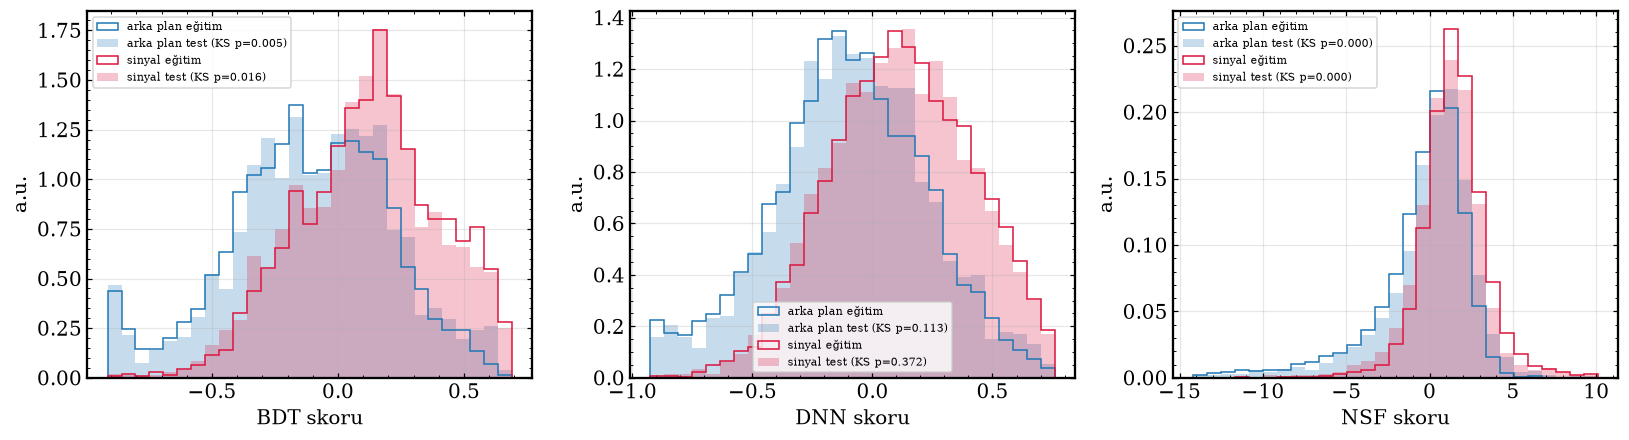

model     sinif         KS_p
  BDT arka plan 5.349227e-03
  BDT    sinyal 1.605012e-02
  DNN arka plan 1.127722e-01
  DNN    sinyal 3.717786e-01
  NSF arka plan 3.996388e-11
  NSF    sinyal 2.231062e-12


In [28]:
from scipy.stats import ks_2samp

b_tr0, b_va0, b_te0 = split3(bkg, 0)
s_tr0, s_va0, s_te0 = split3(sig, 0)
sc0 = StandardScaler().fit(b_tr0[FEATURES])
tf0 = lambda d: sc0.transform(d[FEATURES])
jc0, adim0 = jet_sutunu(FEATURES, sc0)

x_tr0 = np.vstack([tf0(b_tr0), tf0(s_tr0)])
y_tr0 = np.r_[np.zeros(len(b_tr0)), np.ones(len(s_tr0))]
w_tr0 = np.r_[np.full(len(b_tr0), .5 / len(b_tr0)),
             np.full(len(s_tr0), .5 / len(s_tr0))]
x_va0 = np.vstack([tf0(b_va0), tf0(s_va0)])
y_va0 = np.r_[np.zeros(len(b_va0)), np.ones(len(s_va0))]
w_va0 = np.r_[np.full(len(b_va0), .5 / len(b_va0)),
             np.full(len(s_va0), .5 / len(s_va0))]

bdt0, _ = fit_bdt(x_tr0, y_tr0, w_tr0, x_va0, y_va0, w_va0, 0)
dnn0 = fit_dnn(x_tr0, y_tr0, w_tr0, x_va0, y_va0, w_va0, 0)
fsm0 = fit_flow(tf0(b_tr0), tf0(b_va0), 0, jc0, adim0)
fdm0 = fit_flow(tf0(s_tr0), tf0(s_va0), 0, jc0, adim0)
nsf0 = lambda x: log_prob(fdm0, x) - log_prob(fsm0, x)

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
ks_sonuc = []
for a, (ad, sk) in zip(ax, [('BDT', bdt0), ('DNN', dnn0), ('NSF', nsf0)]):
    tr_b, tr_s = sk(tf0(b_tr0)), sk(tf0(s_tr0))
    te_b, te_s = sk(tf0(b_te0)), sk(tf0(s_te0))
    lo, hi = np.percentile(np.r_[tr_b, tr_s, te_b, te_s], [.5, 99.5])
    bins = np.linspace(lo, hi, 30)
    for tr, te, renk, isim in ((tr_b, te_b, 'tab:blue', 'arka plan'),
                               (tr_s, te_s, 'crimson', 'sinyal')):
        p = ks_2samp(tr, te).pvalue
        ks_sonuc.append({'model': ad, 'sinif': isim, 'KS_p': p})
        a.hist(tr, bins=bins, density=True, histtype='step', color=renk,
              label=f'{isim} eğitim')
        a.hist(te, bins=bins, density=True, histtype='stepfilled', color=renk,
              alpha=.25, label=f'{isim} test (KS p={p:.3f})')
    a.set_xlabel(f'{ad} skoru')
    a.set_ylabel('a.u.')
    a.legend(fontsize=7)
    a.grid(alpha=.3)
plt.tight_layout()
plt.savefig(OUT + 'overtraining_ks.pdf', bbox_inches='tight')   # sunum icin
plt.show()
ks_df = pd.DataFrame(ks_sonuc)
ks_df.to_csv(OUT + 'overtraining_ks.csv', index=False)
print(ks_df.to_string(index=False))

## 6d. Değişken önemi (permütasyon)

Her öznitelik **doğrulama** kümesinde sırayla karıştırılır, AUC'deki düşüş ölçülür. Test
kümesi kullanılmaz: bu grafiğe bakılarak öznitelik değiştirilirse test kümesi seçime sızmış
olurdu. BDT ile değişken önemi, modelin skor için hangi girdilere en çok dayandığını gösterir;
fizikle (örn. $E_T^{\rm miss}$'in baskın olması) tutarlılık bir sağlamadır. Türetilme ilişkisi
olan öznitelikler (§1g) önemi paylaşır: biri karıştırılınca diğeri bilgiyi kısmen taşımaya
devam eder, bu yüzden düşük önem "gereksiz" anlamına gelmeyebilir.

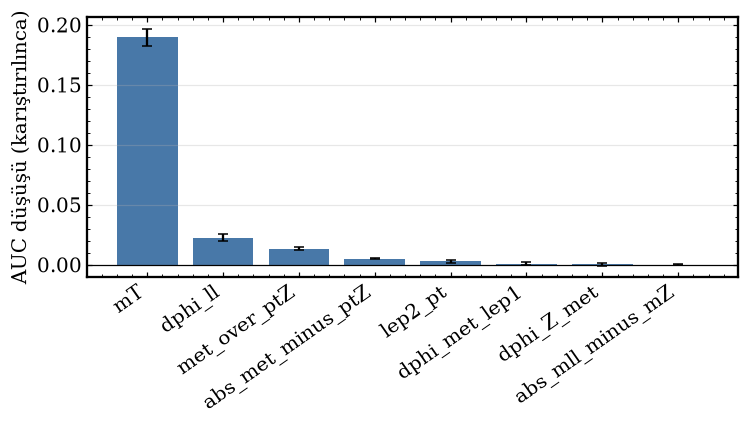

In [29]:
def perm_importance(score_fn, tf, b_te, s_te, F, n_tekrar=5, seed=0):
    """Her ozellik karistirilir, AUC dususu olculur.

    score_fn olceklenmis (StandardScaler sonrasi) girdi bekler; bu yuzden
    DataFrame'i once tf ile donusturup sonra score_fn'e verilir.
    """
    rng = np.random.default_rng(seed)
    yt = np.r_[np.zeros(len(b_te)), np.ones(len(s_te))]
    taban = roc_auc_score(yt, np.r_[score_fn(tf(b_te)), score_fn(tf(s_te))])
    sonuc = {}
    for f in F:
        dusus = []
        for _ in range(n_tekrar):
            bc, sc_ = b_te.copy(), s_te.copy()
            tum = np.r_[bc[f].to_numpy(), sc_[f].to_numpy()]
            rng.shuffle(tum)
            bc[f], sc_[f] = tum[:len(bc)], tum[len(bc):]
            auc = roc_auc_score(yt, np.r_[score_fn(tf(bc)), score_fn(tf(sc_))])
            dusus.append(taban - auc)
        sonuc[f] = (np.mean(dusus), np.std(dusus))
    return sonuc

imp = perm_importance(bdt0, tf0, b_va0, s_va0, FEATURES)   # dogrulama
sira = sorted(FEATURES, key=lambda f: -imp[f][0])
fig, a = plt.subplots(figsize=(7, 4))
a.bar(sira, [imp[f][0] for f in sira], yerr=[imp[f][1] for f in sira],
     color='#4878a8', capsize=3)
a.axhline(0, color='k', lw=.8)
a.set_ylabel('AUC düşüşü (karıştırılınca)')
a.set_xticks(range(len(sira)), sira, rotation=35, ha='right')
a.grid(alpha=.3, axis='y')
plt.tight_layout()
plt.savefig(OUT + 'permutation_importance.pdf', bbox_inches='tight')   # sunum icin
plt.show()
pd.DataFrame({'ozellik': sira, 'onem': [imp[f][0] for f in sira],
             'sd': [imp[f][1] for f in sira]}).to_csv(
    OUT + 'permutation_importance.csv', index=False)

## 7. Yorum ve sınırlamalar

**Ne ölçüldü.** Üç yöntem aynı olaylar, öznitelikler ve bölünmelerle
karşılaştırıldı; sınıflandırma başarısı (AUC, SIC) ve fizik anlamlılığı ($Z_A$)
ayrı ayrı raporlandı. Sayılar yukarıdaki hücrelerin çıktısıdır.

**Sınırlamalar.**

1. **İstatistik.** Kullanılan DY örneği, CERN Open Data'daki 2890 dosyanın
   küçük bir alt kümesidir; bir DY olayı bir $ZZ$ olayından yüzlerce kat ağırdır
   (§1a). Bell ve ark.'nın MC istatistiği gerekliliğini sağlamayan süreçler §2b
   tablosundadır. Bu, $Z_A$'nın baskın belirsizlik kaynağıdır ve beş bölünme
   arasındaki yayılımı açıklar; her çalışma noktasında $N_{\rm eff}\ge10$
   koşulu bu yüzden uygulanır.
2. **Negatif ağırlıklar.** DY'de (payı §1a'da); hücre yeniden örneklemesiyle yerel
   olarak eritildi (toplam ağırlık korunur), ancak yöntem kalan ağırlık
   dalgalanmasını tamamen gidermez.
3. **Sistematikler yok.** $Z_A$ yalnızca istatistiksel bir ölçüttür; jet enerji
   ölçeği, lepton verimliliği, ışınlılık ve pile-up belirsizlikleri dahil
   edilmemiştir. Dolayısıyla bu sayılar **keşif anlamlılığı veya dışlama
   limiti değildir**; yöntem karşılaştırma ölçütüdür.
4. **$w_{\rm PU}$ ve $SF_\mu$ = 1.** Gerçek çarpışma verisi kullanılmadığından
   uyulacak bir referans yoktur; ayrıca ortak çarpanlar $S/B$ oranında büyük
   ölçüde sadeleşir.
5. **Hiperparametre taraması yok.** Üç model de temel kurulumda bırakılmıştır;
   sıralama ayar bütçesine duyarlı olabilir.
6. **Öznitelik seçimi tek bölünmede.** Seçim (§1g) tohum 0'ın eğitim kümesinde
   yapılmıştır; tohum 1–4'ün test kümeleri bu kümeyle kısmen örtüştüğünden bu
   tohumlarda küçük bir iyimser sapma olabilir.
7. **Bell ve ark. (2012) ile karşılaştırma.** Kesimler ve MC istatistiği koşulu
   makaleden alınmıştır (§2b); enerji, lepton kanalı, dedektör simülasyonu ve DM
   modeli farklı olduğu için yalnızca seçimin mantığı karşılaştırılır.

### Veri Seti ve Modelleme Sınırlamaları

Bu analiz, CERN Open Data `RunIIFall15MiniAODv2` campaign verileri kullanılarak
saf bir Monte Carlo (MC) kapanış testi olarak tasarlanmıştır. Veri setinin
dönemsel kısıtları, analizin bazı güncel deneysel yaklaşımlardan
farklılaşmasına neden olmuştur:

* **Sinyal Modelleme.** Analizde 2015-dönemi EFT tarzı basitleştirilmiş
  modeller (axial, vector, scalar) kullanılmıştır. Güncel Run-2
  analizlerinde standart olan 2HDM+a veya modern $Z^\prime$ benchmark
  modelleri, kullanılan açık veri campaign'inde henüz erişilebilir
  olmadığı için sürece dahil edilememiştir.
* **Drell-Yan İstatistikleri ve Kesiklikler.** Drell-Yan arka planı için
  dilimli (binned) veri setleri bu campaign'de bulunmadığından, tek bir
  kapsayıcı (inclusive) NLO seti (`DYJetsToLL_M-50`) kullanılmıştır.
  Hesaplama kısıtları nedeniyle devasa veri setinin ($\sim$2890 dosya)
  yalnızca küçük bir alt kümesi işlenebilmiş, bu da olay başına yüksek
  ağırlıklar (§1a) ve düşük istatistik kaynaklı dağılım
  kesiklikleri yaratmıştır. Bu yapay dalgalanmalar, $N_{\rm eff}$-uyarlamalı
  binleme ve hücre yeniden örnekleme yöntemleriyle sönümlenmiştir (bkz. §1d).
* **Veri-Güdümlü Arka Plan Kısıtı.** Gerçek çarpışma verisi kullanılmadığı
  için $t\bar{t}$ ve $tW$ arka planlarının farklı lezzet ($e\mu$) kontrol
  bölgelerinden veri-güdümlü (data-driven) yöntemlerle ölçülmesi mümkün
  olmamış; tüm arka planlar doğrudan simülasyondan alınmıştır.

**Sonraki adım.** DY'yi MC yerine veri kontrol bölgesinden kestirmek ve örneklem
istatistiğini artırmak; NSF için CR eğitimli kurulumun ekstrapolasyon hatasını
nicelemek.

Öğretmen modelin kararının kısa, okunabilir formüllere indirgenmesi (symbolic regression)
Ek A'dadır.

*Kaynak:* CMS Collaboration, CERN Open Data Portal,
`RunIIFall15MiniAODv2` (DOI kayıtları `_dosyalar.json` içinde listelidir);
bu çalışma.

## Ek A. Symbolic regression: öğretmen model ne öğrendi?

Ana sonuç §5'teki üç modelin karşılaştırmasıdır; bu ek ona yeni bir sonuç eklemez, onu
**yorumlar**. BDT yüzlerce karar ağacından oluşur ve bir olayı neden sinyal saydığını
göstermez. Symbolic regression, aynı kararı birkaç terimlik, okunabilir bir formülle yeniden
üretmeye çalışır. Formül fiziksel olarak anlamlıysa (MET dengesi, sırt sırta topoloji, dar
açılı lepton çifti) model gerçek fiziği öğrenmiş demektir; değilse simülasyona özgü bir yapıya
dayanıyor olabilir. Formülün ayrıca diğer sinyal noktalarına taşınıp taşınamadığı ve enerji
ölçeği kaymalarına ne kadar duyarlı olduğu ölçülür.

### A.1 Yöntem

| Mod | Kütüphane | Hedef |
| --- | --- | --- |
| A, damıtma (*distillation*) | `pyoperon` `SymbolicRegressor` | öğretmenin (§3 BDT) out-of-fold logiti $s=\log[p/(1-p)]$; amaçlar $R^2$ ve formül uzunluğu (Pareto cephesi) |
| B, doğrudan sınıflandırma | `gplearn` `SymbolicClassifier` | sinyal / arka plan etiketi; uzunluk `parsimony_coefficient` ile cezalandırılır |

Girdiler boyutsuzdur:

| Değişken | Tanım | Fiziksel anlam |
| --- | --- | --- |
| $r$ | $E_T^{\rm miss}/p_T^{\ell\ell}$ | $Z$ ile görünmez sistemin dengesi; sinyalde $\approx1$ |
| $x$ | $E_T^{\rm miss}/m_Z$ | MET ölçeği |
| $\Delta\phi$ | $\Delta\phi(\ell\ell, E_T^{\rm miss})$ | sırt sırta topoloji; sinyalde $\approx\pi$ |
| $\Delta R$ | $\Delta R(\ell,\ell)$ | hızlı $Z$'nin dar açılı lepton çifti |
| $\delta m$ | $(m_{\ell\ell}-m_Z)/\Gamma_Z$ | $Z$ kütle çekimi |
| $\Delta\phi_j$ | $\min\Delta\phi({\rm jet}, E_T^{\rm miss})$, jet yoksa $\pi$ | sahte MET (yanlış ölçülmüş jet) |

Protokol defterle aynıdır: §1g'nin seçtiği öznitelikler, aynı 60/20/20 bölünme (tohum 0),
eşik doğrulama kümesinde, anlamlılık (`asimov`) test kümesinde. Öğretmenin hedef logitleri
5 katlı out-of-fold üretilir; formül araması test olaylarını hiç görmez. Seçilen formül,
doğrulama anlamlılığının en büyük değerinin %95'ine ulaşan en kısa formüldür. Karşılaştırma
referansları: Bell ve ark. (2012) kesimleri (§2b) ve öğretmen modelin kendisi.

Hesap `symbolic/` modülündedir ve bu defterin tanımlarını değiştirmeden kullanır; çalıştırma
sırası README'dedir. Aşağıdaki hücreler yalnızca modülün yazdığı sonuçları gösterir.

**Literatürdeki yeri.** Bell ve ark. (2012) makine öğrenmesi kullanmaz; seçimi elle konmuş
kesimlerle yapar. Symbolic regression'ın parçacık fiziğindeki örnekleri farklı amaçlara
yöneliktir: optimal gözlenebilirlerin kapalı formda bulunması (Butter ve ark.), kinematik
formüllerin veriden türetilmesi (Dong ve ark.), jet etiketlemede hızlı çıkarım (Tsoi ve ark.),
hassas LHC fenomenolojisi (Morales-Alvarado ve ark.) ve BSM parametre uzaylarının analitik
yaklaşımı (AbdusSalam ve ark.). Taramamızda mono-$Z$ (ya da genel olarak mono-$X$) olay
seçimini bir öğretmen modelden formüle damıtan bir çalışma bulunamadı; bu ek bu açıdan
keşif niteliğindedir.

*Kaynak:* M. Schmidt, H. Lipson, Science **324** (2009) 81 (symbolic regression);
B. Burlacu, G. Kronberger, M. Kommenda, GECCO '20 Companion (2020) 1562 (Operon);
T. Stephens, *gplearn*; M. Cranmer ve ark., NeurIPS **33** (2020), arXiv:2006.11287 (sinir
ağlarından formül damıtma); A. Butter, T. Plehn, N. Soybelman, J. Brehmer, SciPost Phys.
**16** (2024) 037, arXiv:2109.10414; Z. Dong, K. Kong, K. T. Matchev, K. Matcheva, Phys. Rev. D
**107** (2023) 055018, arXiv:2211.08420; H. F. Tsoi ve ark., arXiv:2305.04099;
M. Morales-Alvarado ve ark., arXiv:2412.07839; S. AbdusSalam, S. Abel, M. Crispim Romão,
arXiv:2405.18471.

### A.2 Sonuçlar

In [30]:
from pathlib import Path
from IPython.display import Image, Markdown, display

_ozet = Path(OUT) / 'summary.md'
if _ozet.exists():
    display(Markdown(_ozet.read_text(encoding='utf-8')))
else:
    print(f"{_ozet} yok: once README'deki symbolic/ adimlarini calistirin.")

/work/results/summary.md yok: once README'deki symbolic/ adimlarini calistirin.


In [31]:
for _ad in ('sr_uzunluk_anlamlilik.png', 'sr_secilen_A_yigin.png',
            'sr_secilen_B_yigin.png', 'ogretmen_asiri_ogrenme.png',
            'ogretmen_degisken_onemi.png'):
    _p = Path(OUT) / _ad
    if _p.exists():
        display(Markdown(f'**{_ad}**'))
        display(Image(filename=str(_p)))

### A.3 Nasıl okunmalı?

- **Formül ile kesim tabanlı seçim:** formülün $Z_A$'sı Bell ve ark. kesimlerininkinden
  büyükse formül, basit kesimlerin göremediği bir ilişkiyi yakalıyor demektir.
- **Formül ile öğretmen:** $Z_A$(formül) / $Z_A$(öğretmen) oranı, BDT'nin ayırma gücünün ne
  kadarının birkaç terimle geri kazanıldığını gösterir.
- **Terimler fiziksel mi:** özetteki türev yönleri beklentiyle uyumlu olmalıdır: $x$ artınca
  sinyal yönüne, $\Delta R$ küçülünce sinyal yönüne, $\Delta\phi\to\pi$ iken sinyal yönüne.
- **Taşınabilirlik:** oran diğer sinyal noktalarında da 1'e yakınsa formül tek bir modele
  özgü değildir.
- **Sistematik:** $|\Delta Z/Z|$ formülde öğretmenden küçükse formül enerji ölçeği
  belirsizliğine karşı daha sağlamdır.

**Sınırlamalar.** Ana analizin istatistik kısıtları (§7) burada da geçerlidir. pyoperon olay
ağırlığını doğrudan almadığı için A modunda ağırlık, ağırlıkla orantılı yeniden örneklemeyle
uygulanır. Fiziksel olarak anlamlı bir formül fiziği kanıtlamaz, yalnızca öğretmenin kararıyla
tutarlı ve yorumlanabilir bir özet sunar.